In [1]:
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif, VarianceThreshold, SelectKBest
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.base import clone
import subprocess
import shutil

# 1) Carregamento dos dados

In [2]:
# Caminhos
DATA_DIR = Path(".")
ZIP_PATH = DATA_DIR / "condition monitoring of hydraulic systems.zip"

# Extrair o dataset
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

# 2) EDA (Análise Exploratória dos dados)

In [3]:
# Listar os arquivos extraídos
arquivos = sorted(DATA_DIR.rglob("*"))

for arquivo in arquivos:
    if arquivo.is_file():
        tamanho_mb = arquivo.stat().st_size / (1024 * 1024)

        print(f"{arquivo.name:<30} {tamanho_mb:.2f} MB")

Algoritmo.ipynb                0.66 MB
README.md                      0.00 MB
REGISTRO_REFERENCIAS.md        0.00 MB
matrizes_confusao_vertical.pdf 0.01 MB
matrizes_confusao_vertical.png 0.05 MB
main.tex                       0.00 MB
refs.bib                       0.01 MB
abstract.tex                   0.00 MB
conclusao.tex                  0.00 MB
introducao.tex                 0.00 MB
metodologia.tex                0.01 MB
resultados.tex                 0.01 MB
trabalhos-relacionados.tex     0.01 MB
tabela1_desempenho.tex         0.00 MB
tabela2_modelos_pc.tex         0.00 MB
tabela3_qemu.tex               0.00 MB
tabela4_distribuicao.tex       0.00 MB
tabela5_validacao.tex          0.00 MB
tabela6_arquiteturas.tex       0.00 MB
tabela7_reducao.tex            0.00 MB
tabela8_calibracao.tex         0.00 MB
Artigo_UniSENAI_revisado_Overleaf.zip 0.08 MB
CE.txt                         0.87 MB
CP.txt                         0.74 MB
EPS1.txt                       83.36 MB
FS1.txt          

In [4]:
# Nomeando as colunas do arquivo de rótulos

## Nomes das colunas
colunas = [
    "resfriador",
    "valvula",
    "bomba",
    "acumulador",
    "estabilidade"
]

## Carregando os rótulos
df_rotulos = pd.read_csv(
    "condition monitoring of hydraulic systems/profile.txt",
    sep=r"\s+",
    header=None,
    names=colunas
)

In [5]:
# Visualizando os dados do arquivo de rótulos

## Dimensáo do DataFrame e primeiras linhas
print("Dimensões:", df_rotulos.shape)
display(df_rotulos.head())

## Verificando a distribuição das condições da bomba (coluna "bomba" do DataFrame)
print("\nCondições da bomba:")
print(df_rotulos["bomba"].value_counts().sort_index())

## Verificando a existência de valores ausentes
print("\nValores ausentes:")
print(df_rotulos.isnull().sum())

Dimensões: (2205, 5)


,resfriador,valvula,bomba,acumulador,estabilidade
0,3,100,0,130,1
1,3,100,0,130,1
2,3,100,0,130,1
3,3,100,0,130,1
4,3,100,0,130,1



Condições da bomba:
0    1221
1     492
2     492
Name: bomba, dtype: int64

Valores ausentes:
resfriador      0
valvula         0
bomba           0
acumulador      0
estabilidade    0
dtype: int64


In [6]:
# Verificando a distribuição dos rótulos das demais colunas do DataFrame

for coluna in df_rotulos.columns:
    print(f"\n{coluna.upper()}")
    print(df_rotulos[coluna].value_counts().sort_index())


RESFRIADOR
3      732
20     732
100    741
Name: resfriador, dtype: int64

VALVULA
73      360
80      360
90      360
100    1125
Name: valvula, dtype: int64

BOMBA
0    1221
1     492
2     492
Name: bomba, dtype: int64

ACUMULADOR
90     808
100    399
115    399
130    599
Name: acumulador, dtype: int64

ESTABILIDADE
0    1449
1     756
Name: estabilidade, dtype: int64


In [7]:
# Verificando os dados de um dos ssensores de temperatura (TS1) do sistema hidráulico

## Carregando os dados do sensor de temperatura TS1
sensor_path = DATA_DIR / "condition monitoring of hydraulic systems" / "TS1.txt"
df_ts1 = pd.read_csv(sensor_path, sep=r"\s+", header=None)

## Imprimindo as dimensões do DataFrame e as primeiras linhas
print("Dimensões:", df_ts1.shape)
display(df_ts1.iloc[:5, :10])

## Verificando a existência de valores ausentes no DataFrame do sensor TS1
print("Valores ausentes:", df_ts1.isnull().sum().sum())

Dimensões: (2205, 60)


,0,1,2,3,4,5,6,7,8,9
0,35.570,35.492,35.469,35.422,35.414,35.320,35.227,35.242,35.160,35.176
1,36.156,36.094,35.992,36.008,35.992,35.902,35.824,35.820,35.727,35.727
2,37.488,37.391,37.340,37.312,37.223,37.145,37.059,36.973,36.898,36.879
3,38.633,38.535,38.469,38.379,38.297,38.223,38.125,38.062,37.977,37.969
4,39.461,39.461,39.375,39.281,39.203,39.113,39.043,38.969,38.875,38.883


Valores ausentes: 0


In [8]:
# Verificando a quantidade de medições por ciclo para cada sensor do nosso dataset

## Pasta onde se encontra os arquivos de dados dos sensores
pasta = sensor_path.parent

## Identificando os arquivos dos sensores
sensores = sorted(
    arquivo for arquivo in pasta.glob("*.txt")
    if arquivo.stem.startswith(("PS", "FS", "TS", "VS", "EPS", "CE", "CP", "SE"))
)

## Verificando a quantidade de medições por ciclo
for arquivo in sensores:
    with open(arquivo) as f:
        primeira_linha = f.readline()

    n_medicoes = len(primeira_linha.split())

    print(f"{arquivo.stem:<6} | {n_medicoes:>5} medições por ciclo")

print(f"\nTotal de sensores/variáveis: {len(sensores)}")

CE     |    60 medições por ciclo
CP     |    60 medições por ciclo
EPS1   |  6000 medições por ciclo
FS1    |   600 medições por ciclo
FS2    |   600 medições por ciclo
PS1    |  6000 medições por ciclo
PS2    |  6000 medições por ciclo
PS3    |  6000 medições por ciclo
PS4    |  6000 medições por ciclo
PS5    |  6000 medições por ciclo
PS6    |  6000 medições por ciclo
SE     |    60 medições por ciclo
TS1    |    60 medições por ciclo
TS2    |    60 medições por ciclo
TS3    |    60 medições por ciclo
TS4    |    60 medições por ciclo
VS1    |    60 medições por ciclo

Total de sensores/variáveis: 17


# 3) Feature Engineering

In [9]:
# Extraindo características de cada ciclo (60s) para cada sensor do dataset

features = []

for arquivo in sensores:
    
    ## Carregar os dados de uma variável por vez
    df = pd.read_csv(
        arquivo,
        sep="\t",
        header=None,
        dtype=np.float32
    )

    ## Extrair as características de cada ciclo de 60 segundos (1 minuto) para cada sensor
    df_features = pd.DataFrame({
        f"{arquivo.stem}_mean": df.mean(axis=1),
        f"{arquivo.stem}_std": df.std(axis=1, ddof=1),
        f"{arquivo.stem}_min": df.min(axis=1),
        f"{arquivo.stem}_max": df.max(axis=1)
    })

    ## Adicionar as features extraídas à lista de features
    features.append(df_features)
    print(f"{arquivo.stem}: concluído")
    del df

## Criando uma tabela com todas as features extraídas de cada sensor
X = pd.concat(features, axis=1)

## Verificando as dimensões do DataFrame de features
print("\nDimensões:", X.shape)

## Verificando a existência de valores ausentes no DataFrame de features
print("Valores ausentes:", X.isnull().sum().sum())

## Visualizando as primeiras linhas do DataFrame de features
display(X.head())

CE: concluído
CP: concluído
EPS1: concluído
FS1: concluído
FS2: concluído
PS1: concluído
PS2: concluído
PS3: concluído
PS4: concluído
PS5: concluído
PS6: concluído
SE: concluído
TS1: concluído
TS2: concluído
TS3: concluído
TS4: concluído
VS1: concluído

Dimensões: (2205, 68)
Valores ausentes: 0


,CE_mean,CE_std,CE_min,CE_max,CP_mean,CP_std,CP_min,CP_max,EPS1_mean,EPS1_std,...,TS3_min,TS3_max,TS4_mean,TS4_std,TS4_min,TS4_max,VS1_mean,VS1_std,VS1_min,VS1_max
0,39.601345,6.370535,28.865999,47.438000,1.862750,0.279385,1.383,2.188,2538.977783,185.614334,...,38.316002,38.612999,31.745258,1.116478,30.363001,33.594002,0.576950,0.027078,0.532,0.624
1,25.786434,1.686129,23.320000,29.208000,1.255550,0.074605,1.147,1.414,2531.571777,189.939438,...,38.667999,39.254002,34.493858,0.435312,33.647999,35.147999,0.565850,0.027241,0.524,0.626
2,22.218231,0.638345,21.219999,23.554001,1.113217,0.023263,1.076,1.159,2519.982666,190.737030,...,39.234001,40.062000,35.646160,0.293889,35.098000,36.140999,0.576533,0.036729,0.529,0.662
3,20.459816,0.455755,19.673000,21.565001,1.062150,0.024621,1.022,1.107,2511.614258,191.272156,...,40.022999,40.933998,36.579468,0.262397,36.105000,36.987999,0.569267,0.033464,0.527,0.645
4,19.787018,0.290156,19.132999,20.459999,1.070467,0.021477,1.016,1.106,2503.528564,191.258774,...,40.859001,41.777000,37.427906,0.239570,36.992001,37.780998,0.577367,0.033484,0.524,0.660


In [10]:
# Verificando a correspondência entre os dataset de features e dos rótulos

## Verificar correspondência entre features e rótulos
assert len(X) == len(df_rotulos)
assert X.index.equals(df_rotulos.index)

## Criar tabela completa
df_completo = pd.concat([X, df_rotulos], axis=1)

## Verificando as dimensões do DataFrame completo
print("Dimensões:", df_completo.shape)
display(df_completo.head())

Dimensões: (2205, 73)


,CE_mean,CE_std,CE_min,CE_max,CP_mean,CP_std,CP_min,CP_max,EPS1_mean,EPS1_std,...,TS4_max,VS1_mean,VS1_std,VS1_min,VS1_max,resfriador,valvula,bomba,acumulador,estabilidade
0,39.601345,6.370535,28.865999,47.438000,1.862750,0.279385,1.383,2.188,2538.977783,185.614334,...,33.594002,0.576950,0.027078,0.532,0.624,3,100,0,130,1
1,25.786434,1.686129,23.320000,29.208000,1.255550,0.074605,1.147,1.414,2531.571777,189.939438,...,35.147999,0.565850,0.027241,0.524,0.626,3,100,0,130,1
2,22.218231,0.638345,21.219999,23.554001,1.113217,0.023263,1.076,1.159,2519.982666,190.737030,...,36.140999,0.576533,0.036729,0.529,0.662,3,100,0,130,1
3,20.459816,0.455755,19.673000,21.565001,1.062150,0.024621,1.022,1.107,2511.614258,191.272156,...,36.987999,0.569267,0.033464,0.527,0.645,3,100,0,130,1
4,19.787018,0.290156,19.132999,20.459999,1.070467,0.021477,1.016,1.106,2503.528564,191.258774,...,37.780998,0.577367,0.033484,0.524,0.660,3,100,0,130,1


In [11]:
# Verificando a coluna da BOMBA no dataset de rótulos

# Definir a variável alvo
# 0 = Sem vazamento
# 1 = Vazamento leve
# 2 = Vazamento severo

y_bomba = df_rotulos["bomba"].astype(int)

# Verificar distribuição das classes
print("Distribuição das classes:")
print(y_bomba.value_counts().sort_index())

# Verificar relação entre condição da bomba e estabilidade
print("\nBomba × Estabilidade:")
display(pd.crosstab(df_rotulos["bomba"], df_rotulos["estabilidade"]))

Distribuição das classes:
0    1221
1     492
2     492
Name: bomba, dtype: int64

Bomba × Estabilidade:


estabilidade,0,1
bomba,,
0,489,732
1,480,12
2,480,12


In [12]:
# Verificando a coluna do ACUMULADOR no dataset de rótulos

# Definir a variável-alvo
# 90  = Próximo da falha total
# 100 = Pressão severamente reduzida
# 115 = Pressão ligeiramente reduzida
# 130 = Pressão ideal

y_acumulador = df_rotulos["acumulador"].astype(int)

# Verificar distribuição das classes
print("Distribuição das classes:")
print(y_acumulador.value_counts().sort_index())

# Verificar relação entre condição do acumulador e estabilidade
print("\nAcumulador × Estabilidade:")
display(pd.crosstab(df_rotulos["acumulador"], df_rotulos["estabilidade"]))

Distribuição das classes:
90     808
100    399
115    399
130    599
Name: acumulador, dtype: int64

Acumulador × Estabilidade:


estabilidade,0,1
acumulador,,
90,369,439
100,360,39
115,360,39
130,360,239


In [13]:
# Verificando os valores únicos da coluna do ACUMULADOR no dataset de rótulos

y_acumulador.unique()

array([130, 115, 100,  90])

In [14]:
# Verificando a estrutura do DataFrame completo

df_completo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2205 entries, 0 to 2204
Data columns (total 73 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   CE_mean       2205 non-null   float32
 1   CE_std        2205 non-null   float32
 2   CE_min        2205 non-null   float32
 3   CE_max        2205 non-null   float32
 4   CP_mean       2205 non-null   float32
 5   CP_std        2205 non-null   float32
 6   CP_min        2205 non-null   float32
 7   CP_max        2205 non-null   float32
 8   EPS1_mean     2205 non-null   float32
 9   EPS1_std      2205 non-null   float32
 10  EPS1_min      2205 non-null   float32
 11  EPS1_max      2205 non-null   float32
 12  FS1_mean      2205 non-null   float32
 13  FS1_std       2205 non-null   float32
 14  FS1_min       2205 non-null   float32
 15  FS1_max       2205 non-null   float32
 16  FS2_mean      2205 non-null   float32
 17  FS2_std       2205 non-null   float32
 18  FS2_min       2205 non-null 

In [15]:
# Verificando as estatísticas descritivas do DataFrame completo

df_completo.describe()

,CE_mean,CE_std,CE_min,CE_max,CP_mean,CP_std,CP_min,CP_max,EPS1_mean,EPS1_std,...,TS4_max,VS1_mean,VS1_std,VS1_min,VS1_max,resfriador,valvula,bomba,acumulador,estabilidade
count,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,...,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000
mean,31.299065,0.287325,30.785683,31.880314,1.808399,0.022692,1.769091,1.855767,2495.564453,203.489517,...,40.811264,0.613315,0.042999,0.555920,0.725865,41.240816,90.693878,0.669388,107.199546,0.342857
std,11.575332,0.199760,11.583488,11.602731,0.278263,0.011138,0.282245,0.278504,73.838959,27.766148,...,8.129013,0.060260,0.032313,0.040783,0.153986,42.383143,10.681802,0.817233,16.435848,0.474772
min,17.555983,0.063165,17.042000,18.142000,1.062150,0.006914,1.016000,1.105000,2361.801758,185.105331,...,30.422001,0.524367,0.012673,0.483000,0.562000,3.000000,73.000000,0.000000,90.000000,0.000000
25%,20.084648,0.217363,19.513000,20.694000,1.550100,0.018377,1.502000,1.604000,2442.992188,188.986252,...,31.309000,0.555100,0.026018,0.516000,0.614000,3.000000,80.000000,0.000000,90.000000,0.000000
50%,27.392536,0.264125,26.862000,27.983000,1.739683,0.021472,1.701000,1.786000,2480.997070,196.153702,...,40.452999,0.610183,0.032527,0.561000,0.689000,20.000000,100.000000,0.000000,100.000000,0.000000
75%,46.677383,0.329684,46.167999,47.271999,2.148483,0.025096,2.115000,2.190000,2548.276123,198.927505,...,49.495998,0.649850,0.048122,0.582000,0.785000,100.000000,100.000000,1.000000,130.000000,1.000000
max,47.903664,6.370535,47.625999,48.777000,2.840100,0.343522,2.768000,2.909000,2740.717041,294.047729,...,53.145000,0.839067,0.465159,0.696000,2.546000,100.000000,100.000000,2.000000,130.000000,1.000000


# 4) Divisão dos dados em treino e teste

In [16]:
# Identificar grupos de ciclos consecutivos com as mesmas condições
componentes = ["resfriador", "valvula", "bomba", "acumulador"]

mudancas = df_rotulos[componentes].ne(
    df_rotulos[componentes].shift()
).any(axis=1)

grupos = mudancas.cumsum()

## 4.1) Bomba

In [17]:
# Dividir o dataset em treinamento e teste,
# mantendo a proporção das três classes e evitando grupos compartilhados

# Classes da BOMBA
classes = [0, 1, 2]

# Calcular a distribuição das três classes no dataset original
distribuicao_original = (
    y_bomba.value_counts(normalize=True)
    .reindex(classes, fill_value=0)
)

# Gerar 500 divisões candidatas
divisor = GroupShuffleSplit(
    n_splits=500,
    test_size=0.2,
    random_state=42
)


# Definir o valor inicial do melhor erro
melhor_erro = float("inf")


# Avaliar as 500 divisões candidatas
for treino, teste in divisor.split(X, y_bomba, groups=grupos):

    # Garantir que treinamento e teste contenham as três classes
    if (
        y_bomba.iloc[treino].nunique() < 3
        or y_bomba.iloc[teste].nunique() < 3
    ):
        continue

    # Calcular a proporção de registros destinados ao teste
    proporcao_teste = len(teste) / len(X)

    # Calcular a distribuição das três classes no teste
    distribuicao_teste = (
        y_bomba.iloc[teste]
        .value_counts(normalize=True)
        .reindex(classes, fill_value=0)
    )

    # Calcular o erro da divisão candidata
    erro = (
        abs(proporcao_teste - 0.2)
        + (distribuicao_teste - distribuicao_original).abs().sum()
    )

    # Armazenar a divisão com o menor erro
    if erro < melhor_erro:
        melhor_erro = erro
        idx_treino_bomba = treino
        idx_teste_bomba = teste


# Verificar se uma divisão válida foi encontrada
assert melhor_erro < float("inf"), "Nenhuma divisão válida encontrada."


# Criar os conjuntos de treinamento e teste
X_treino_bomba = X.iloc[idx_treino_bomba]
X_teste_bomba = X.iloc[idx_teste_bomba]

y_treino_bomba = y_bomba.iloc[idx_treino_bomba]
y_teste_bomba  = y_bomba.iloc[idx_teste_bomba]

# Selecionar os grupos correspondentes ao treinamento
grupos_treino_bomba = grupos.iloc[idx_treino_bomba]

In [18]:
# Verificando a proporção de falhas nos conjuntos de treinamento e teste

# Quantidade total de registros
total = len(X)

# Quantidade de registros por conjunto
n_treino_bomba = len(X_treino_bomba)
n_teste_bomba = len(X_teste_bomba)

# Calcular percentuais
pct_treino = (n_treino_bomba / total) * 100
pct_teste = (n_teste_bomba / total) * 100

# Exibir resultados
print(f"Total de registros: {total}")
print(f"Treinamento: {n_treino_bomba} registros ({pct_treino:.2f}%)")
print(f"Teste:       {n_teste_bomba} registros ({pct_teste:.2f}%)")

Total de registros: 2205
Treinamento: 1697 registros (76.96%)
Teste:       508 registros (23.04%)


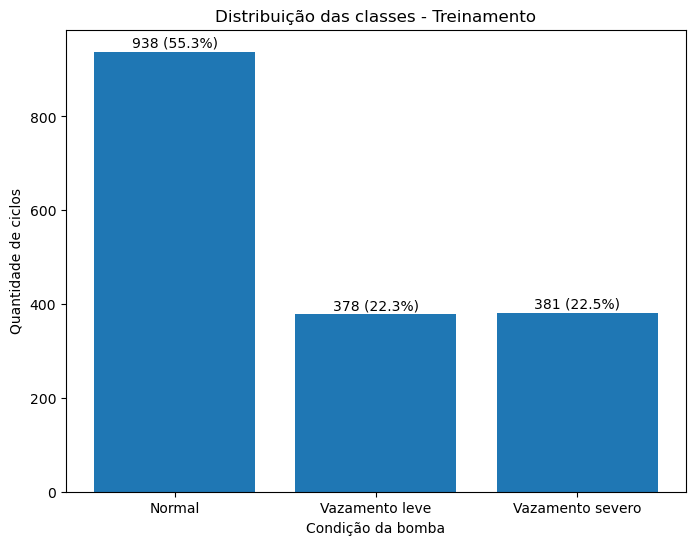

In [19]:
# Verificando a proporção de falhas nos conjuntos de treinamento da BOMBA

# Distribuição das classes
contagem_bomba = y_treino_bomba.value_counts().sort_index()

# Mostrar quantidade e percentual acima das barras
total_bomba = contagem_bomba.sum()

# ráfico
plt.figure(figsize=(8, 6))

plt.bar(
    ["Normal", "Vazamento leve", "Vazamento severo"],
    contagem_bomba.values
)

plt.title("Distribuição das classes - Treinamento")
plt.xlabel("Condição da bomba")
plt.ylabel("Quantidade de ciclos")

# Mostrar valores acima das barras
for i, valor in enumerate(contagem_bomba.values):
    percentual = (valor / total_bomba) * 100
    plt.text(i, valor + 10, f"{valor} ({percentual:.1f}%)", ha="center")

plt.show()

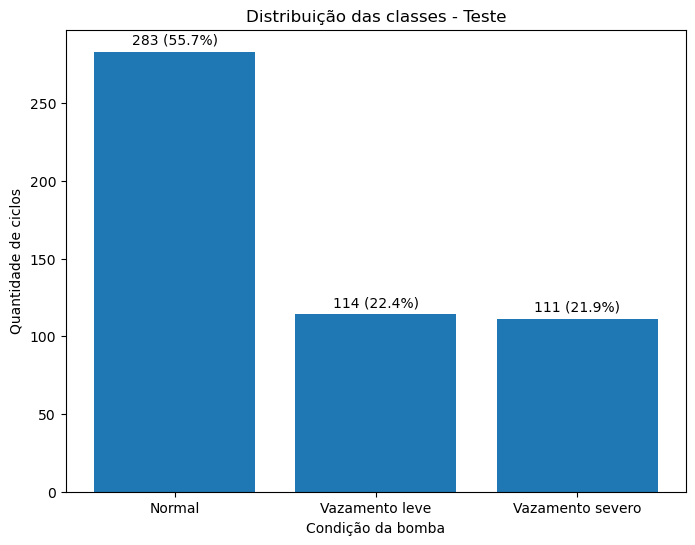

In [20]:
# Verificando a proporção de falhas nos conjuntos de teste

# Distribuição das classes no teste
contagem_bomba = y_teste_bomba.value_counts().sort_index()
total_bomba = contagem_bomba.sum()

plt.figure(figsize=(8, 6))

plt.bar(
    ["Normal", "Vazamento leve", "Vazamento severo"],
    contagem_bomba.values
)

plt.title("Distribuição das classes - Teste")
plt.xlabel("Condição da bomba")
plt.ylabel("Quantidade de ciclos")

# Quantidade e percentual
for i, valor in enumerate(contagem_bomba.values):
    percentual = (valor / total_bomba) * 100
    plt.text(i, valor + 5, f"{valor} ({percentual:.1f}%)", ha="center")

plt.show()

## b) Acumulador

In [21]:
# Divisão estratificada por grupos - ACUMULADOR

classes_acumulador = [90, 100, 115, 130]

# Identificar o tamanho de cada grupo e sua classe
df_grupos = pd.DataFrame({
    "Grupo": grupos.to_numpy(),
    "Classe": y_acumulador.to_numpy()
})

tamanho_grupos = (
    df_grupos.groupby(["Classe", "Grupo"])
    .size()
    .reset_index(name="Ciclos")
)

# Distribuição original
distribuicao_original = (
    y_acumulador.value_counts(normalize=True)
    .reindex(classes_acumulador, fill_value=0)
)

rng = np.random.RandomState(42)

divisao_encontrada = False

# Realizar até 1000 tentativas
for tentativa in range(1000):

    grupos_teste = []

    # Selecionar grupos separadamente para cada classe
    for classe in classes_acumulador:

        grupos_classe = tamanho_grupos[
            tamanho_grupos["Classe"] == classe
        ]

        # Objetivo: aproximadamente 20% dos ciclos da classe
        alvo = round((y_acumulador == classe).sum() * 0.20)

        quantidade = 0

        # Percorrer os grupos em ordem aleatória
        ordem = rng.permutation(len(grupos_classe))

        for posicao in ordem:

            grupo = grupos_classe.iloc[posicao]

            if quantidade + grupo["Ciclos"] <= alvo:

                grupos_teste.append(grupo["Grupo"])
                quantidade += grupo["Ciclos"]

    # Identificar os registros selecionados
    mascara_teste = grupos.isin(grupos_teste).to_numpy()

    treino = np.flatnonzero(~mascara_teste)
    teste = np.flatnonzero(mascara_teste)

    # Verificar a proporção do teste
    proporcao_teste = len(teste) / len(X)

    # Verificar a distribuição das classes
    distribuicao_treino = (
        y_acumulador.iloc[treino]
        .value_counts(normalize=True)
        .reindex(classes_acumulador, fill_value=0)
    )

    distribuicao_teste = (
        y_acumulador.iloc[teste]
        .value_counts(normalize=True)
        .reindex(classes_acumulador, fill_value=0)
    )

    diferenca_treino = (
        distribuicao_treino - distribuicao_original
    ).abs().max()

    diferenca_teste = (
        distribuicao_teste - distribuicao_original
    ).abs().max()

    # Verificar os critérios
    if (
        0.18 <= proporcao_teste <= 0.22
        and diferenca_treino <= 0.05
        and diferenca_teste <= 0.05
    ):

        idx_treino_acumulador = treino
        idx_teste_acumulador = teste

        divisao_encontrada = True
        break

assert divisao_encontrada, "Nenhuma divisão válida encontrada."

# Criar os conjuntos
X_treino_acumulador = X.iloc[idx_treino_acumulador]
X_teste_acumulador = X.iloc[idx_teste_acumulador]

y_treino_acumulador = y_acumulador.iloc[idx_treino_acumulador]
y_teste_acumulador = y_acumulador.iloc[idx_teste_acumulador]

grupos_treino_acumulador = grupos.iloc[idx_treino_acumulador]

# Verificar ausência de grupos compartilhados
assert set(grupos_treino_acumulador).isdisjoint(
    set(grupos.iloc[idx_teste_acumulador])
)

print("Tentativas necessárias:", tentativa + 1)
print("Treinamento:", len(X_treino_acumulador))
print("Teste:", len(X_teste_acumulador))

Tentativas necessárias: 1
Treinamento: 1766
Teste: 439


In [22]:
# Verificando a proporção de falhas nos conjuntos de treinamento e teste

# Quantidade total de registros
total = len(X)

# Quantidade de registros por conjunto
n_treino_acumulador = len(X_treino_acumulador)
n_teste_acumulador = len(X_teste_acumulador)

# Calcular percentuais
pct_treino = (n_treino_acumulador / total) * 100
pct_teste = (n_teste_acumulador / total) * 100

# Exibir resultados
print(f"Total de registros: {total}")
print(f"Treinamento: {n_treino_acumulador} registros ({pct_treino:.2f}%)")
print(f"Teste:       {n_teste_acumulador} registros ({pct_teste:.2f}%)")

Total de registros: 2205
Treinamento: 1766 registros (80.09%)
Teste:       439 registros (19.91%)


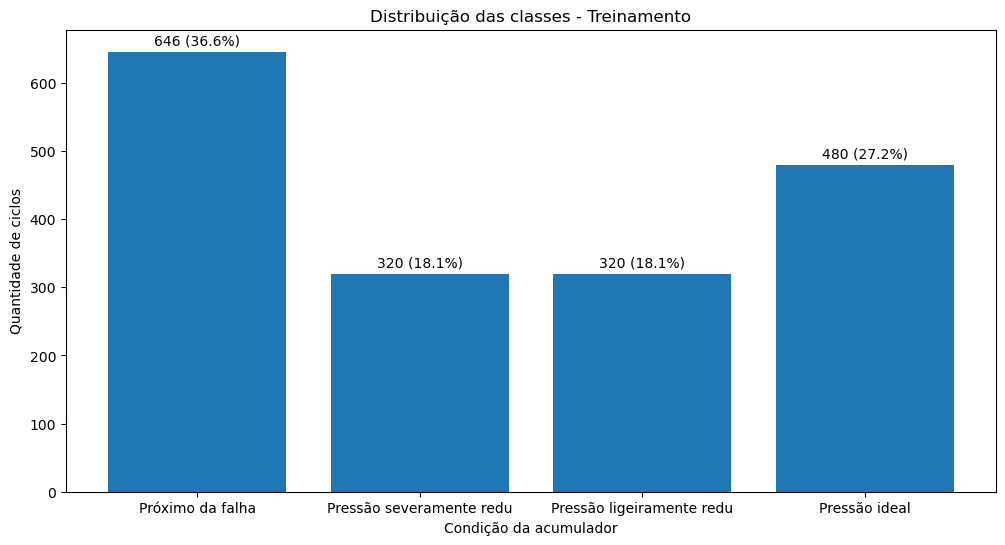

In [23]:
# Verificando a proporção de falhas nos conjuntos de treinamento do ACUMULADOR

# Distribuição das classes
contagem_acumulador = y_treino_acumulador.value_counts().sort_index()

# Mostrar quantidade e percentual acima das barras
total_acumulador = contagem_acumulador.sum()

# ráfico
plt.figure(figsize=(12, 6))

plt.bar(
    ["Próximo da falha", "Pressão severamente redu", "Pressão ligeiramente redu", "Pressão ideal"],
    contagem_acumulador.values
)

plt.title("Distribuição das classes - Treinamento")
plt.xlabel("Condição da acumulador")
plt.ylabel("Quantidade de ciclos")

# Mostrar valores acima das barras
for i, valor in enumerate(contagem_acumulador.values):
    percentual = (valor / total_acumulador) * 100
    plt.text(i, valor + 10, f"{valor} ({percentual:.1f}%)", ha="center")

plt.show()

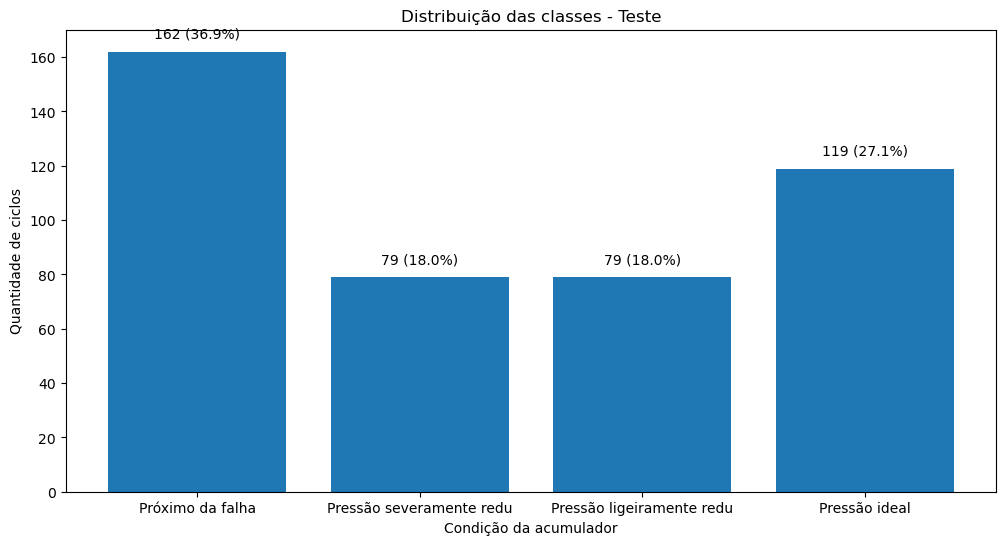

In [24]:
# Verificando a proporção de falhas nos conjuntos de teste do ACUMULADOR

# Distribuição das classes no teste
contagem_acumulador = y_teste_acumulador.value_counts().sort_index()
total_acumulador = contagem_acumulador.sum()

plt.figure(figsize=(12, 6))

plt.bar(
    ["Próximo da falha", "Pressão severamente redu", "Pressão ligeiramente redu", "Pressão ideal"],
    contagem_acumulador.values
)

plt.title("Distribuição das classes - Teste")
plt.xlabel("Condição da acumulador")
plt.ylabel("Quantidade de ciclos")

# Quantidade e percentual
for i, valor in enumerate(contagem_acumulador.values):
    percentual = (valor / total_acumulador) * 100
    plt.text(i, valor + 5, f"{valor} ({percentual:.1f}%)", ha="center")

plt.show()

# 5) EDA aprofundada: somente com os dados de treinamento

## 5.1) Bomba

In [25]:
# Estatísticas descritivas das features

estatisticas_bomba = X_treino_bomba.describe().T

display(estatisticas_bomba)

,count,mean,std,min,25%,50%,75%,max
CE_mean,1697.0,31.704895,12.206901,17.555983,19.916689,27.514126,46.752487,47.903664
CE_std,1697.0,0.291689,0.218397,0.063165,0.218314,0.267735,0.335592,6.370535
CE_min,1697.0,31.180420,12.214283,17.042000,19.337000,26.985001,46.270000,47.625999
CE_max,1697.0,32.293140,12.236176,18.142000,20.504999,28.127001,47.355999,48.777000
CP_mean,1697.0,1.812401,0.296549,1.062150,1.538233,1.744867,2.152416,2.840100
...,...,...,...,...,...,...,...,...
TS4_max,1697.0,40.789055,8.628243,30.422001,31.226999,40.202999,49.683998,53.145000
VS1_mean,1697.0,0.615673,0.064171,0.524367,0.552850,0.612600,0.655833,0.829550
VS1_std,1697.0,0.044608,0.034343,0.012673,0.025286,0.031912,0.051824,0.315645
VS1_min,1697.0,0.556875,0.043039,0.483000,0.514000,0.564000,0.586000,0.696000


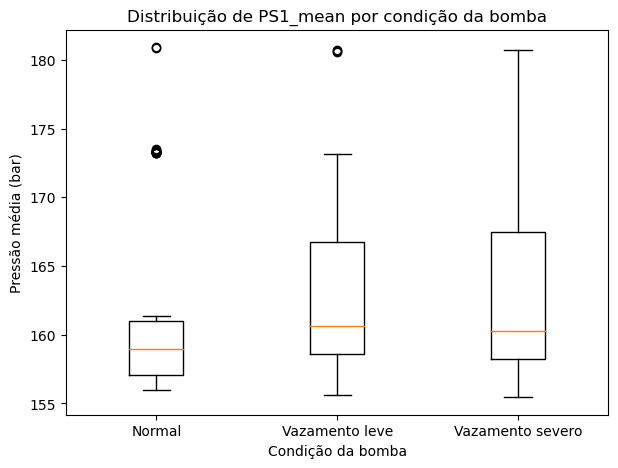

In [26]:
# Distribuição de uma feature por condição da bomba

# Selecionando a feature
feature = "PS1_mean"

# Separando os valores por classe
normal = X_treino_bomba.loc[y_treino_bomba == 0, feature]
vazamento_leve = X_treino_bomba.loc[y_treino_bomba == 1, feature]
vazamento_severo = X_treino_bomba.loc[y_treino_bomba == 2, feature]

# Criando o gráfico
plt.figure(figsize=(7, 5))

plt.boxplot(
    [normal, vazamento_leve, vazamento_severo],
    labels=["Normal", "Vazamento leve", "Vazamento severo"]
)

plt.title(f"Distribuição de {feature} por condição da bomba")
plt.xlabel("Condição da bomba")
plt.ylabel("Pressão média (bar)")

plt.show()

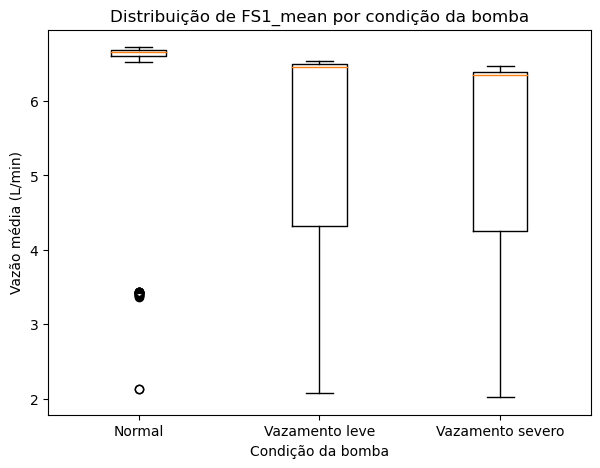

In [27]:
# Distribuição de uma feature por condição da bomba

# Selecionando a feature
feature = "FS1_mean"

# Separando os valores por classe
normal = X_treino_bomba.loc[y_treino_bomba == 0, feature]
vazamento_leve = X_treino_bomba.loc[y_treino_bomba == 1, feature]
vazamento_severo = X_treino_bomba.loc[y_treino_bomba  == 2, feature]

# Criando o gráfico
plt.figure(figsize=(7, 5))

plt.boxplot(
    [normal, vazamento_leve, vazamento_severo],
    labels=["Normal", "Vazamento leve", "Vazamento severo"]
)

plt.title(f"Distribuição de {feature} por condição da bomba")
plt.xlabel("Condição da bomba")
plt.ylabel("Vazão média (L/min)")

plt.show()

In [28]:
# Correlação das 68 features com o rótulo da bomba (Correlação de Pearson)

# Correlação das 68 features com o rótulo da bomba
correlacoes_bomba = X_treino_bomba.corrwith(y_treino_bomba)

# Ordenar pela intensidade da correlação
correlacoes_bomba = correlacoes_bomba.reindex(
    correlacoes_bomba.abs().sort_values(ascending=False).index
)


# Mostrar as 15 maiores correlações
display(correlacoes_bomba.head(15))

SE_mean     -0.469750
FS1_mean    -0.425027
EPS1_mean    0.398429
PS3_mean    -0.380434
PS2_std      0.350333
PS1_max     -0.344857
EPS1_std     0.337356
PS1_std      0.327418
PS1_mean     0.308473
PS2_mean     0.305722
VS1_min      0.217703
VS1_std     -0.215188
VS1_mean     0.171520
FS1_max      0.171397
VS1_max     -0.167291
dtype: float64

In [29]:
# Verificando a correlação entre as features do dataset (Correlação de Pearson)

# Correlação entre as 68 features
matriz_corr_bomba = X_treino_bomba.corr().abs()

mascara_bomba = np.triu(
    np.ones(matriz_corr_bomba.shape, dtype=bool),
    k=1
)

pares_bomba = matriz_corr_bomba.where(mascara_bomba).stack()
pares_bomba = pares_bomba.sort_values(ascending=False)

display(pares_bomba.head(15))

print("Pares com correlação > 0.95:", (pares_bomba > 0.95).sum())

PS5_mean  PS6_mean    0.999993
TS3_mean  TS3_max     0.999988
          TS3_min     0.999985
TS1_mean  TS1_max     0.999981
PS5_max   PS6_max     0.999980
TS2_mean  TS2_min     0.999973
PS5_min   PS6_min     0.999972
TS2_mean  TS2_max     0.999968
TS1_mean  TS1_min     0.999965
TS3_min   TS3_max     0.999960
TS4_mean  TS4_min     0.999953
          TS4_max     0.999949
PS5_min   PS6_mean    0.999944
PS5_mean  PS5_min     0.999944
          PS6_max     0.999942
dtype: float64

Pares com correlação > 0.95: 353


In [30]:
# Calcular o F-score de cada feature para as três classes

# Identificar features não constantes
X_anova_bomba = X_treino_bomba.loc[
    :, X_treino_bomba.nunique() > 1
]

# Calcular ANOVA
f_scores_bomba, p_valores_bomba = f_classif(
    X_anova_bomba,
    y_treino_bomba
)

# Organizar os resultados
df_f_scores_bomba = pd.DataFrame({
    "Feature": X_anova_bomba.columns,
    "F-score": f_scores_bomba,
    "p-valor": p_valores_bomba
})

df_f_scores_bomba = df_f_scores_bomba.sort_values(
    by="F-score",
    ascending=False
)

display(df_f_scores_bomba.head(15))

,Feature,F-score,p-valor
42,SE_mean,276.387390,0.000000e+00
12,FS1_mean,217.487991,0.000000e+00
8,EPS1_mean,174.505447,0.000000e+00
27,PS3_mean,160.224213,0.000000e+00
25,PS2_std,145.798065,0.000000e+00
23,PS1_max,143.338455,0.000000e+00
9,EPS1_std,130.130920,0.000000e+00
21,PS1_std,121.816956,0.000000e+00
20,PS1_mean,112.120338,0.000000e+00
24,PS2_mean,108.221542,5.605194e-45


In [31]:
# Identificar as três features apontadas pelo Scikit-learn
indices_constantes = [26, 30, 46]

features_constantes = X_treino_bomba.columns[indices_constantes]

print("Features constantes:")
print(features_constantes.tolist())

# Verificar seus valores
display(
    X_treino_bomba[features_constantes].describe()
)

Features constantes:
['PS2_min', 'PS3_min', 'SE_min']


,PS2_min,PS3_min,SE_min
count,1697.0,1697.0,1697.0
mean,0.0,0.0,0.0
std,0.0,0.0,0.0
min,0.0,0.0,0.0
25%,0.0,0.0,0.0
50%,0.0,0.0,0.0
75%,0.0,0.0,0.0
max,0.0,0.0,0.0


In [32]:
# Identificar features constantes — BOMBA
features_constantes_bomba = (
    X_treino_bomba.columns[
        X_treino_bomba.nunique() <= 1
    ].tolist()
)

print("Features constantes:", features_constantes_bomba)

Features constantes: ['PS2_min', 'PS3_min', 'SE_min']


## 5.2) Acumulador

In [33]:
# Estatísticas descritivas das features — ACUMULADOR
estatisticas_acumulador = X_treino_acumulador.describe().T

display(estatisticas_acumulador)

,count,mean,std,min,25%,50%,75%,max
CE_mean,1766.0,31.605482,11.718771,17.555983,20.072026,27.367098,46.708028,47.903664
CE_std,1766.0,0.289441,0.218459,0.101799,0.218030,0.264363,0.327862,6.370535
CE_min,1766.0,31.086384,11.726041,17.042000,19.490250,26.850500,46.202499,47.625999
CE_max,1766.0,32.189789,11.746900,18.142000,20.669250,27.987000,47.318501,48.777000
CP_mean,1766.0,1.815027,0.284625,1.062150,1.549558,1.739700,2.150062,2.840100
...,...,...,...,...,...,...,...,...
TS4_max,1766.0,40.598560,8.132723,30.422001,31.233999,40.519499,49.272249,53.082001
VS1_mean,1766.0,0.610471,0.058498,0.529433,0.554971,0.607675,0.646979,0.829550
VS1_std,1766.0,0.042842,0.031602,0.012673,0.025711,0.032560,0.047888,0.315645
VS1_min,1766.0,0.553888,0.039738,0.483000,0.516000,0.558000,0.581000,0.686000


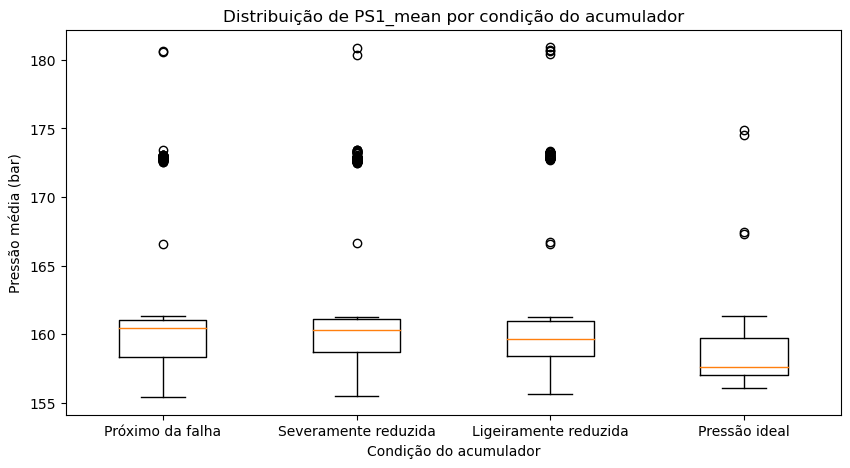

In [34]:
# Distribuição de uma feature por condição do acumulador

# Selecionar a feature
feature = "PS1_mean"

# Separar os valores por classe
proximo_da_falha = X_treino_acumulador.loc[y_treino_acumulador == 90, feature]
pressao_severamente_reduzida = X_treino_acumulador.loc[y_treino_acumulador == 100, feature]
pressao_ligeiramente_reduzida = X_treino_acumulador.loc[y_treino_acumulador == 115, feature]
pressao_ideal = X_treino_acumulador.loc[y_treino_acumulador == 130, feature]

# Criar o gráfico
plt.figure(figsize=(10, 5))

plt.boxplot(
    [
        proximo_da_falha,
        pressao_severamente_reduzida,
        pressao_ligeiramente_reduzida,
        pressao_ideal
    ],
    labels=[
        "Próximo da falha",
        "Severamente reduzida",
        "Ligeiramente reduzida",
        "Pressão ideal"
    ]
)

plt.title(f"Distribuição de {feature} por condição do acumulador")
plt.xlabel("Condição do acumulador")
plt.ylabel("Pressão média (bar)")

plt.show()

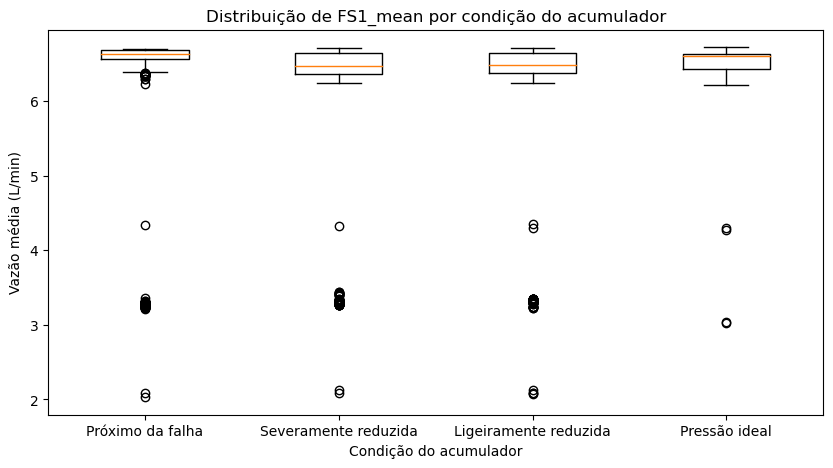

In [35]:
# Distribuição de uma feature por condição do acumulador

# Selecionar a feature
feature = "FS1_mean"

# Separar os valores por classe
proximo_da_falha = X_treino_acumulador.loc[y_treino_acumulador == 90, feature]
pressao_severamente_reduzida = X_treino_acumulador.loc[y_treino_acumulador == 100, feature]
pressao_ligeiramente_reduzida = X_treino_acumulador.loc[y_treino_acumulador == 115, feature]
pressao_ideal = X_treino_acumulador.loc[y_treino_acumulador == 130, feature]

# Criar o gráfico
plt.figure(figsize=(10, 5))

plt.boxplot(
    [
        proximo_da_falha,
        pressao_severamente_reduzida,
        pressao_ligeiramente_reduzida,
        pressao_ideal
    ],
    labels=[
        "Próximo da falha",
        "Severamente reduzida",
        "Ligeiramente reduzida",
        "Pressão ideal"
    ]
)

plt.title(f"Distribuição de {feature} por condição do acumulador")
plt.xlabel("Condição do acumulador")
plt.ylabel("Vazão média (L/min)")

plt.show()

In [36]:
# Correlação das 68 features com o rótulo da acumulador (Correlação de Pearson)

# Correlação das 68 features com o rótulo da acumulador
correlacoes_acumulador = X_treino_acumulador.corrwith(y_treino_acumulador)

# Ordenar pela intensidade da correlação
correlacoes_acumulador = correlacoes_acumulador.reindex(
    correlacoes_acumulador.abs().sort_values(ascending=False).index
)

# Mostrar as 15 maiores correlações
display(correlacoes_acumulador.head(15))

FS1_max      0.432693
PS3_max      0.362626
TS1_std      0.319806
CP_min      -0.278533
CP_max      -0.278362
CP_mean     -0.278360
PS2_max     -0.264293
PS1_min     -0.262843
PS1_max     -0.260722
VS1_min      0.239555
PS6_min     -0.234996
CE_min      -0.234244
EPS1_mean   -0.233731
PS5_min     -0.233577
CE_mean     -0.233029
dtype: float64

In [37]:
# Verificando a correlação entre as features do dataset (Correlação de Pearson)

# Correlação entre as 68 features
matriz_corr_acumulador = X_treino_acumulador.corr().abs()

# Considerar apenas a parte superior da matriz
mascara_acumulador = np.triu(
    np.ones(matriz_corr_acumulador.shape, dtype=bool),
    k=1
)

# Identificar pares de features correlacionadas
pares_acumulador = matriz_corr_acumulador.where(mascara_acumulador).stack()

# Ordenar pelas maiores correlações
pares_acumulador = pares_acumulador.sort_values(ascending=False)

# Mostrar os 15 pares mais correlacionados
display(pares_acumulador.head(15))

# Contar correlações muito fortes
print("Pares com correlação > 0.95:", (pares_acumulador > 0.95).sum())

PS5_mean  PS6_mean    0.999993
TS3_mean  TS3_max     0.999987
          TS3_min     0.999983
TS1_mean  TS1_max     0.999980
PS5_max   PS6_max     0.999978
PS5_min   PS6_min     0.999970
TS2_mean  TS2_min     0.999969
          TS2_max     0.999967
TS1_mean  TS1_min     0.999958
TS3_min   TS3_max     0.999954
TS4_mean  TS4_min     0.999944
          TS4_max     0.999944
PS5_mean  PS5_min     0.999939
PS5_min   PS6_mean    0.999938
PS5_mean  PS6_max     0.999937
dtype: float64

Pares com correlação > 0.95: 337


In [38]:
# Calcular o F-score de cada feature para as quatro classes

# Identificar features não constantes
X_anova_acumulador = X_treino_acumulador.loc[
    :, X_treino_acumulador.nunique() > 1
]

# Calcular ANOVA
f_scores_acumulador, p_valores_acumulador = f_classif(
    X_anova_acumulador,
    y_treino_acumulador
)

# Organizar os resultados
df_f_scores_acumulador = pd.DataFrame({
    "Feature": X_anova_acumulador.columns,
    "F-score": f_scores_acumulador,
    "p-valor": p_valores_acumulador
})

df_f_scores_acumulador = df_f_scores_acumulador.sort_values(
    by="F-score",
    ascending=False
)

display(df_f_scores_acumulador.head(15))

,Feature,F-score,p-valor
15,FS1_max,181.005234,0.000000e+00
29,PS3_max,95.333183,0.000000e+00
46,TS1_std,81.574585,0.000000e+00
8,EPS1_mean,71.028687,2.312142e-43
23,PS1_max,68.828125,4.351032e-42
20,PS1_mean,59.399010,1.406339e-36
7,CP_max,57.103226,3.169748e-35
4,CP_mean,56.851204,4.464978e-35
6,CP_min,56.622948,6.090173e-35
42,SE_mean,53.823555,2.764462e-33


In [39]:
# Identificar as três features apontadas pelo Scikit-learn
indices_constantes = [26, 30, 46]
    
features_constantes = X_treino_acumulador.columns[indices_constantes]

print("Features constantes:")
print(features_constantes.tolist())

# Verificar seus valores
display(
    X_treino_acumulador[features_constantes].describe()
)

Features constantes:
['PS2_min', 'PS3_min', 'SE_min']


,PS2_min,PS3_min,SE_min
count,1766.0,1766.0,1766.0
mean,0.0,0.0,0.0
std,0.0,0.0,0.0
min,0.0,0.0,0.0
25%,0.0,0.0,0.0
50%,0.0,0.0,0.0
75%,0.0,0.0,0.0
max,0.0,0.0,0.0


In [40]:
# Identificar features constantes — ACUMULADOR
features_constantes_acumulador = (
    X_treino_acumulador.columns[
        X_treino_acumulador.nunique() <= 1
    ].tolist()
)

print("Features constantes:", features_constantes_acumulador)

Features constantes: ['PS2_min', 'PS3_min', 'SE_min']


# 6) Treinamento dos modelos

- Serão avaliados Logistic Regression (LR), Decision Tree (DT), Random Forest (RF) e Multilayer Perceptron (MLP) em duas tarefas distintas: bomba (3 classes) e acumulador (4 classes). As configurações iniciais são as mesmas nas duas tarefas.

- Importante: nesta seção são utilizados somente os conjuntos de desenvolvimento (X_treino_bomba e X_treino_acumulador) para ajustar e validar os modelos. Os conjuntos X_teste_* permanecem reservados para a avaliação final. Os rótulos dos componentes usados nos grupos não são fornecidos como entradas dos classificadores.

In [41]:
# Quatro pipelines: remover features constantes SEM consultar a validação.
# A padronização é necessária para LR e MLP, mas não para DT e RF.
# Mantemos os hiperparâmetros iniciais já empregados no estudo.

modelos_base = {
    "LR": make_pipeline(
        VarianceThreshold(threshold=0.0),
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "DT": make_pipeline(
        VarianceThreshold(threshold=0.0),
        DecisionTreeClassifier(max_depth=8, random_state=42)
    ),
    "RF": make_pipeline(
        VarianceThreshold(threshold=0.0),
        RandomForestClassifier(
            n_estimators=100,
            max_depth=8,
            random_state=42,
            n_jobs=-1
        )
    ),
    "MLP": make_pipeline(
        VarianceThreshold(threshold=0.0),
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(16,),
            activation="relu",
            max_iter=1200,
            random_state=42
        )
    )
}

print("Pipelines configurados:", list(modelos_base))

Pipelines configurados: ['LR', 'DT', 'RF', 'MLP']


In [42]:
# Função para gerar divisões equilibradas por grupos
# Cada grupo deve pertencer a somente uma classe. As proporções
# são avaliadas em relação a TODAS as amostras de desenvolvimento.
# 20% das amostras são destinadas à validação, com tolerância de 2%.


def gerar_divisoes_equilibradas(
    y_dados,
    grupos_dados,
    classes,
    n_divisoes=1,
    proporcao_val=0.20,
    tolerancia_tamanho=0.02,
    tolerancia_classes=0.05,
    random_state=42,
    max_tentativas=5000
):
    """Retorna (indices_treino, indices_validacao) por posição.

    Cada grupo deve pertencer a somente uma classe. As proporções
    são avaliadas em relação a TODAS as amostras de desenvolvimento.
    """
    y_arr = np.asarray(y_dados)
    g_arr = np.asarray(grupos_dados)
    classes = list(classes)

    assert len(y_arr) == len(g_arr), "Rótulos e grupos têm tamanhos diferentes."
    assert set(np.unique(y_arr)) == set(classes), "Classes inesperadas no alvo."

    # Para seleção por classe, os grupos não podem conter rótulos diferentes.
    dados_grupos = pd.DataFrame({"grupo": g_arr, "classe": y_arr})
    if (dados_grupos.groupby("grupo")["classe"].nunique() > 1).any():
        raise ValueError("Há grupos contendo mais de uma classe.")

    info = (
        dados_grupos.groupby("grupo")
        .agg(classe=("classe", "first"), tamanho=("classe", "size"))
        .reset_index()
    )
    info_por_classe = {}
    for classe in classes:
        parte = info.loc[info["classe"] == classe]
        info_por_classe[classe] = (
            parte["grupo"].to_numpy(),
            parte["tamanho"].to_numpy(dtype=int)
        )

    distribuicao_base = (
        pd.Series(y_arr).value_counts(normalize=True)
        .reindex(classes, fill_value=0)
    )
    rng = np.random.RandomState(random_state)
    divisoes = []
    assinaturas = set()

    for _ in range(max_tentativas):
        ids_validacao = []

        # Escolher grupos inteiros, separadamente para cada classe.
        for classe in classes:
            ids, tamanhos = info_por_classe[classe]
            alvo = round((y_arr == classe).sum() * proporcao_val)
            total = 0

            for pos in rng.permutation(len(ids)):
                qtd = int(tamanhos[pos])
                if total + qtd <= alvo:
                    ids_validacao.append(ids[pos])
                    total += qtd

        mascara_val = np.isin(g_arr, ids_validacao)
        idx_val = np.flatnonzero(mascara_val)
        idx_fit = np.flatnonzero(~mascara_val)
        if len(idx_val) == 0 or len(idx_fit) == 0:
            continue

        # Evitar divisões com os mesmos grupos de validação.
        assinatura = frozenset(ids_validacao)
        if assinatura in assinaturas:
            continue

        tamanho_val = len(idx_val) / len(y_arr)
        if abs(tamanho_val - proporcao_val) > tolerancia_tamanho:
            continue

        if set(np.unique(y_arr[idx_val])) != set(classes):
            continue
        if set(np.unique(y_arr[idx_fit])) != set(classes):
            continue

        distribuicao_fit = (
            pd.Series(y_arr[idx_fit]).value_counts(normalize=True)
            .reindex(classes, fill_value=0)
        )
        distribuicao_val = (
            pd.Series(y_arr[idx_val]).value_counts(normalize=True)
            .reindex(classes, fill_value=0)
        )
        if (
            (distribuicao_fit - distribuicao_base).abs().max() > tolerancia_classes
            or (distribuicao_val - distribuicao_base).abs().max() > tolerancia_classes
        ):
            continue

        assert set(g_arr[idx_fit]).isdisjoint(set(g_arr[idx_val]))
        assinaturas.add(assinatura)
        divisoes.append((idx_fit, idx_val))
        if len(divisoes) == n_divisoes:
            break

    if len(divisoes) != n_divisoes:
        raise RuntimeError(
            f"Foram encontradas {len(divisoes)} de {n_divisoes} divisões "
            "dentro das tolerâncias. Revise a estrutura dos grupos; "
            "não ajuste os limites automaticamente."
        )
    return divisoes

print("Função de divisão configurada.")

Função de divisão configurada.


In [43]:
# Funções de avaliação de modelos

def tabela_particoes(y_fit, y_val, y_teste, classes):
    """Resumo descritivo das classes; NÃO avalia modelos no teste."""
    linhas = []
    for nome, rotulos in [
        ("Treinamento efetivo", y_fit),
        ("Validação", y_val),
        ("Teste (reservado)", y_teste)
    ]:
        frequencias = (
            rotulos.value_counts(normalize=True)
            .reindex(classes, fill_value=0)
        )
        linha = {"Conjunto": nome, "Registros": len(rotulos)}
        for classe in classes:
            linha[f"Classe {classe} (%)"] = 100 * frequencias.loc[classe]
        linhas.append(linha)
    return pd.DataFrame(linhas)


def treinar_e_validar(modelos_config, X_fit, y_fit, X_val, y_val):
    """Treina quatro modelos novos e calcula as métricas na validação."""
    modelos_treinados = {}
    linhas = []
    for nome, configuracao in modelos_config.items():
        modelo = clone(configuracao)
        modelo.fit(X_fit, y_fit)
        previsto = modelo.predict(X_val)
        modelos_treinados[nome] = modelo
        linhas.append({
            "Modelo": nome,
            "Acurácia": accuracy_score(y_val, previsto),
            "Precision macro": precision_score(
                y_val, previsto, average="macro", zero_division=0
            ),
            "Recall macro": recall_score(
                y_val, previsto, average="macro", zero_division=0
            ),
            "F1 macro": f1_score(
                y_val, previsto, average="macro", zero_division=0
            )
        })
        print(f"{nome}: treinamento e validação concluídos")
    return modelos_treinados, pd.DataFrame(linhas)


def avaliar_robustez(modelos_config, X_dev, y_dev, divisoes, classes):
    """Reajusta os modelos para cada divisão sem acessar o teste final."""
    linhas = []
    for numero, (idx_fit, idx_val) in enumerate(divisoes, start=1):
        X_fit = X_dev.iloc[idx_fit]
        X_val = X_dev.iloc[idx_val]
        y_fit = y_dev.iloc[idx_fit]
        y_val = y_dev.iloc[idx_val]

        for nome, configuracao in modelos_config.items():
            modelo = clone(configuracao)
            modelo.fit(X_fit, y_fit)
            previsto = modelo.predict(X_val)
            linhas.append({
                "Divisão": numero,
                "Modelo": nome,
                "Treinamento": len(idx_fit),
                "Validação": len(idx_val),
                "Acurácia": accuracy_score(y_val, previsto),
                "F1 macro": f1_score(
                    y_val, previsto, labels=classes,
                    average="macro", zero_division=0
                )
            })

    detalhado = pd.DataFrame(linhas)
    resumo = (
        detalhado.groupby("Modelo")["F1 macro"]
        .agg(["count", "mean", "std", "min", "max"])
        .rename(columns={
            "count": "Divisões", "mean": "F1 médio",
            "std": "Desvio-padrão", "min": "F1 mínimo", "max": "F1 máximo"
        })
    )
    return detalhado, resumo

print("Funções de avaliação configuradas.")

Funções de avaliação configuradas.


## 6.1) Bomba

In [44]:
# Divisão entre treinamento e validação — BOMBA

classes_bomba = [0, 1, 2]

# Utilizar SOMENTE os dados reservados para desenvolvimento da bomba.
divisoes_iniciais_bomba = gerar_divisoes_equilibradas(
    y_dados=y_treino_bomba,
    grupos_dados=grupos_treino_bomba,
    classes=classes_bomba,
    n_divisoes=1,
    tolerancia_tamanho=0.02,       # 18% a 22% na validação
    tolerancia_classes=0.05,       # até 5 p.p. por classe
    random_state=21
)
idx_fit_bomba, idx_val_bomba = divisoes_iniciais_bomba[0]

X_fit_bomba = X_treino_bomba.iloc[idx_fit_bomba]
X_val_bomba = X_treino_bomba.iloc[idx_val_bomba]
y_fit_bomba = y_treino_bomba.iloc[idx_fit_bomba]
y_val_bomba = y_treino_bomba.iloc[idx_val_bomba]

# Comparar os grupos de cada conjunto, sempre com índices da mesma origem.
grupos_fit_bomba = set(grupos_treino_bomba.iloc[idx_fit_bomba])
grupos_val_bomba = set(grupos_treino_bomba.iloc[idx_val_bomba])
grupos_teste_bomba = set(grupos.iloc[idx_teste_bomba])
assert grupos_fit_bomba.isdisjoint(grupos_val_bomba)
assert grupos_fit_bomba.isdisjoint(grupos_teste_bomba)
assert grupos_val_bomba.isdisjoint(grupos_teste_bomba)

print("BOMBA — divisão válida; nenhum grupo consecutivo compartilhado.")
display(tabela_particoes(
    y_fit_bomba, y_val_bomba, y_teste_bomba, classes_bomba
).round(2))

BOMBA — divisão válida; nenhum grupo consecutivo compartilhado.


,Conjunto,Registros,Classe 0 (%),Classe 1 (%),Classe 2 (%)
0,Treinamento efetivo,1357,55.27,22.25,22.48
1,Validação,340,55.29,22.35,22.35
2,Teste (reservado),508,55.71,22.44,21.85


In [45]:
# Treinamento e validação dos quatro modelos — BOMBA

modelos_bomba, df_resultados_bomba = treinar_e_validar(
    modelos_base, X_fit_bomba, y_fit_bomba, X_val_bomba, y_val_bomba
)
display(df_resultados_bomba.round(4))

LR: treinamento e validação concluídos
DT: treinamento e validação concluídos
RF: treinamento e validação concluídos
MLP: treinamento e validação concluídos


,Modelo,Acurácia,Precision macro,Recall macro,F1 macro
0,LR,0.9971,0.9957,0.9956,0.9956
1,DT,0.9794,0.9726,0.9745,0.9734
2,RF,0.9941,0.9915,0.9912,0.9912
3,MLP,1.0000,1.0000,1.0000,1.0000


In [46]:
# Matriz de confusão e relatório de classificação — MLP (bomba)

pred_mlp_bomba = modelos_bomba["MLP"].predict(X_val_bomba)
print("BOMBA — Matriz de confusão (linhas = classe real):")
print(confusion_matrix(y_val_bomba, pred_mlp_bomba, labels=classes_bomba))
print("\nRelatório de classificação — MLP (bomba):")
print(classification_report(
    y_val_bomba,
    pred_mlp_bomba,
    labels=classes_bomba,
    target_names=["Sem vazamento", "Vazamento leve", "Vazamento severo"],
    zero_division=0
))

BOMBA — Matriz de confusão (linhas = classe real):
[[188   0   0]
 [  0  76   0]
 [  0   0  76]]

Relatório de classificação — MLP (bomba):
                  precision    recall  f1-score   support

   Sem vazamento       1.00      1.00      1.00       188
  Vazamento leve       1.00      1.00      1.00        76
Vazamento severo       1.00      1.00      1.00        76

        accuracy                           1.00       340
       macro avg       1.00      1.00      1.00       340
    weighted avg       1.00      1.00      1.00       340



In [47]:
# Robustez dos modelos — BOMBA
# Testar a estabilidade dos modelos em 20 divisões diferentes, mantendo a proporção das classes e evitando grupos compartilhados.

# Uma condição experimental = combinação dos quatro rótulos físicos.
# As combinações são usadas SOMENTE para AGRUPAR, nunca como features.


grupos_condicoes_bomba = (
    df_rotulos.loc[X_treino_bomba.index, componentes]
    .astype(str).agg("|".join, axis=1)
)

divisoes_robustez_bomba = gerar_divisoes_equilibradas(
    y_dados=y_treino_bomba,
    grupos_dados=grupos_condicoes_bomba,
    classes=classes_bomba,
    n_divisoes=20,
    tolerancia_tamanho=0.05,       # 15% a 25% na validação
    tolerancia_classes=0.05,       # até 5 p.p. por classe
    random_state=42
)

print("BOMBA — divisões válidas:", len(divisoes_robustez_bomba))

# Conferir o tamanho e as proporções em cada divisão
resumo_divisoes_bomba = []
for numero, (fit, val) in enumerate(divisoes_robustez_bomba, start=1):
    proporcoes = (
        y_treino_bomba.iloc[val].value_counts(normalize=True)
        .reindex(classes_bomba, fill_value=0)
    )
    linha = {
        "Divisão": numero,
        "Treinamento": len(fit),
        "Validação": len(val),
        "% validação": 100 * len(val) / len(X_treino_bomba)
    }
    linha.update({f"Classe {c} (%)": 100 * proporcoes.loc[c]
                  for c in classes_bomba})
    resumo_divisoes_bomba.append(linha)

df_divisoes_bomba = pd.DataFrame(resumo_divisoes_bomba)
display(df_divisoes_bomba.round(2))

BOMBA — divisões válidas: 20


,Divisão,Treinamento,Validação,% validação,Classe 0 (%),Classe 1 (%),Classe 2 (%)
0,1,1365,332,19.56,55.42,21.99,22.59
1,2,1363,334,19.68,54.49,22.75,22.75
2,3,1366,331,19.51,55.29,21.75,22.96
3,4,1366,331,19.51,54.98,22.05,22.96
4,5,1365,332,19.56,55.12,21.99,22.89
5,6,1365,332,19.56,55.12,22.29,22.59
6,7,1366,331,19.51,54.98,22.05,22.96
7,8,1367,330,19.45,54.85,22.12,23.03
8,9,1367,330,19.45,55.15,21.82,23.03
9,10,1364,333,19.62,55.26,21.92,22.82


In [48]:
df_robustez_bomba, resumo_robustez_bomba = avaliar_robustez(
    modelos_base,
    X_treino_bomba,
    y_treino_bomba,
    divisoes_robustez_bomba,
    classes_bomba
)

print("BOMBA — F1 macro nas 20 divisões:")
display(resumo_robustez_bomba.round(4))

BOMBA — F1 macro nas 20 divisões:


,Divisões,F1 médio,Desvio-padrão,F1 mínimo,F1 máximo
Modelo,,,,,
DT,20,0.9162,0.0324,0.8613,0.9712
LR,20,0.9744,0.0202,0.9327,1.0000
MLP,20,0.9700,0.0304,0.8827,0.9955
RF,20,0.9678,0.0385,0.8367,1.0000


## 6.2) Acumulador

In [49]:
# Divisão entre treinamento e validação — ACUMULADOR

classes_acumulador = [90, 100, 115, 130]

# Utilizar SOMENTE os dados reservados para desenvolvimento do acumulador.
divisoes_iniciais_acumulador = gerar_divisoes_equilibradas(
    y_dados=y_treino_acumulador,
    grupos_dados=grupos_treino_acumulador,
    classes=classes_acumulador,
    n_divisoes=1,
    tolerancia_tamanho=0.02,       # 18% a 22% na validação
    tolerancia_classes=0.05,       # até 5 p.p. por classe
    random_state=21
)
idx_fit_acumulador, idx_val_acumulador = divisoes_iniciais_acumulador[0]

X_fit_acumulador = X_treino_acumulador.iloc[idx_fit_acumulador]
X_val_acumulador = X_treino_acumulador.iloc[idx_val_acumulador]
y_fit_acumulador = y_treino_acumulador.iloc[idx_fit_acumulador]
y_val_acumulador = y_treino_acumulador.iloc[idx_val_acumulador]

# Comparar grupos na mesma escala de índices, inclusive no teste original.
grupos_fit_acumulador = set(grupos_treino_acumulador.iloc[idx_fit_acumulador])
grupos_val_acumulador = set(grupos_treino_acumulador.iloc[idx_val_acumulador])
grupos_teste_acumulador = set(grupos.iloc[idx_teste_acumulador])
assert grupos_fit_acumulador.isdisjoint(grupos_val_acumulador)
assert grupos_fit_acumulador.isdisjoint(grupos_teste_acumulador)
assert grupos_val_acumulador.isdisjoint(grupos_teste_acumulador)

print("ACUMULADOR — divisão válida; nenhum grupo consecutivo compartilhado.")
display(tabela_particoes(
    y_fit_acumulador, y_val_acumulador, y_teste_acumulador, classes_acumulador
).round(2))

ACUMULADOR — divisão válida; nenhum grupo consecutivo compartilhado.


,Conjunto,Registros,Classe 90 (%),Classe 100 (%),Classe 115 (%),Classe 130 (%)
0,Treinamento efetivo,1430,36.36,18.18,18.18,27.27
1,Validação,336,37.50,17.86,17.86,26.79
2,Teste (reservado),439,36.90,18.00,18.00,27.11


In [50]:
# Treinamento e validação dos quatro modelos — ACUMULADOR

modelos_acumulador, df_resultados_acumulador = treinar_e_validar(
    modelos_base,
    X_fit_acumulador,
    y_fit_acumulador,
    X_val_acumulador,
    y_val_acumulador
)
display(df_resultados_acumulador.round(4))

LR: treinamento e validação concluídos
DT: treinamento e validação concluídos
RF: treinamento e validação concluídos
MLP: treinamento e validação concluídos


,Modelo,Acurácia,Precision macro,Recall macro,F1 macro
0,LR,0.7500,0.7295,0.7466,0.7280
1,DT,0.6042,0.6235,0.6619,0.6080
2,RF,0.7381,0.7540,0.7748,0.7345
3,MLP,0.8185,0.7952,0.8123,0.7975


In [51]:
# Matriz de confusão e relatório de classificação — MLP (acumulador)

pred_mlp_acumulador = modelos_acumulador["MLP"].predict(X_val_acumulador)
print("ACUMULADOR — Matriz de confusão (linhas = classe real):")
print(confusion_matrix(y_val_acumulador, pred_mlp_acumulador,
                       labels=classes_acumulador))
print("\nRelatório de classificação — MLP (acumulador):")
print(classification_report(
    y_val_acumulador,
    pred_mlp_acumulador,
    labels=classes_acumulador,
    target_names=["Próximo da falha", "Pressão severamente reduzida",
                  "Pressão ligeiramente reduzida", "Pressão ideal"],
    zero_division=0
))

ACUMULADOR — Matriz de confusão (linhas = classe real):
[[107  18   1   0]
 [  2  56   2   0]
 [  2   8  40  10]
 [  0   0  18  72]]

Relatório de classificação — MLP (acumulador):
                               precision    recall  f1-score   support

             Próximo da falha       0.96      0.85      0.90       126
 Pressão severamente reduzida       0.68      0.93      0.79        60
Pressão ligeiramente reduzida       0.66      0.67      0.66        60
                Pressão ideal       0.88      0.80      0.84        90

                     accuracy                           0.82       336
                    macro avg       0.80      0.81      0.80       336
                 weighted avg       0.84      0.82      0.82       336



In [52]:
# Robustez dos modelos — ACUMULADOR

grupos_condicoes_acumulador = (
    df_rotulos.loc[X_treino_acumulador.index, componentes]
    .astype(str).agg("|".join, axis=1)
)

divisoes_robustez_acumulador = gerar_divisoes_equilibradas(
    y_dados=y_treino_acumulador,
    grupos_dados=grupos_condicoes_acumulador,
    classes=classes_acumulador,
    n_divisoes=20,
    tolerancia_tamanho=0.05,       # 15% a 25% na validação
    tolerancia_classes=0.05,       # até 5 p.p. por classe
    random_state=43
)

print("ACUMULADOR — divisões válidas:", len(divisoes_robustez_acumulador))

resumo_divisoes_acumulador = []
for numero, (fit, val) in enumerate(divisoes_robustez_acumulador, start=1):
    proporcoes = (
        y_treino_acumulador.iloc[val].value_counts(normalize=True)
        .reindex(classes_acumulador, fill_value=0)
    )
    linha = {
        "Divisão": numero,
        "Treinamento": len(fit),
        "Validação": len(val),
        "% validação": 100 * len(val) / len(X_treino_acumulador)
    }
    linha.update({f"Classe {c} (%)": 100 * proporcoes.loc[c]
                  for c in classes_acumulador})
    resumo_divisoes_acumulador.append(linha)

df_divisoes_acumulador = pd.DataFrame(resumo_divisoes_acumulador)
display(df_divisoes_acumulador.round(2))

ACUMULADOR — divisões válidas: 20


,Divisão,Treinamento,Validação,% validação,Classe 90 (%),Classe 100 (%),Classe 115 (%),Classe 130 (%)
0,1,1431,335,18.97,37.31,17.91,17.91,26.87
1,2,1434,332,18.80,36.75,18.07,18.07,27.11
2,3,1432,334,18.91,37.13,17.96,17.96,26.95
3,4,1432,334,18.91,37.13,17.96,17.96,26.95
4,5,1433,333,18.86,36.94,18.02,18.02,27.03
5,6,1433,333,18.86,36.94,18.02,18.02,27.03
6,7,1431,335,18.97,37.31,17.91,17.91,26.87
7,8,1432,334,18.91,37.13,17.96,17.96,26.95
8,9,1431,335,18.97,37.31,17.91,17.91,26.87
9,10,1433,333,18.86,36.94,18.02,18.02,27.03


In [53]:
df_robustez_acumulador, resumo_robustez_acumulador = avaliar_robustez(
    modelos_base,
    X_treino_acumulador,
    y_treino_acumulador,
    divisoes_robustez_acumulador,
    classes_acumulador
)

print("ACUMULADOR — F1 macro nas 20 divisões:")
display(resumo_robustez_acumulador.round(4))

ACUMULADOR — F1 macro nas 20 divisões:


,Divisões,F1 médio,Desvio-padrão,F1 mínimo,F1 máximo
Modelo,,,,,
DT,20,0.5522,0.0773,0.4375,0.7172
LR,20,0.6350,0.0595,0.5320,0.7332
MLP,20,0.7589,0.0731,0.6303,0.8744
RF,20,0.6544,0.0800,0.5203,0.8236


### 6.2.1) Comparação de arquiteturas MLP para o acumulador

In [54]:
# Comparação de diferentes arquiteturas MLP — ACUMULADOR

from sklearn.neural_network import MLPClassifier

# Definir as arquiteturas
arquiteturas = {
    "MLP 16": (16,),
    "MLP 32": (32,),
    "MLP 64": (64,),
    "MLP 64-32": (64, 32),
    "MLP 128-64": (128, 64)
}

# Definir os grupos experimentais
grupos_cv = (
    df_rotulos.loc[X_treino_acumulador.index, componentes]
    .astype(str)
    .agg("|".join, axis=1)
)

# Configurar GroupKFold
divisor_cv = GroupKFold(n_splits=5)

resultados_arquiteturas = []

# Avaliar cada arquitetura
for nome, arquitetura in arquiteturas.items():

    for numero, (treino, val) in enumerate(
        divisor_cv.split(
            X_treino_acumulador,
            y_treino_acumulador,
            groups=grupos_cv
        ),
        start=1
    ):

        # Separar os dados
        X_tr = X_treino_acumulador.iloc[treino]
        X_va = X_treino_acumulador.iloc[val]

        y_tr = y_treino_acumulador.iloc[treino]
        y_va = y_treino_acumulador.iloc[val]

        # Criar MLP com a arquitetura desejada
        mlp = clone(
            modelos_base["MLP"].named_steps["mlpclassifier"]
        )

        mlp.set_params(
            hidden_layer_sizes=arquitetura,
            max_iter=2000,
            random_state=42
        )

        # Pipeline completo
        modelo = make_pipeline(
            VarianceThreshold(),
            StandardScaler(),
            mlp
        )

        # Treinamento
        modelo.fit(X_tr, y_tr)

        # Validação
        previsoes = modelo.predict(X_va)

        mlp_treinada = modelo.named_steps["mlpclassifier"]

        # Quantidade de parâmetros
        parametros = (
            sum(w.size for w in mlp_treinada.coefs_)
            + sum(b.size for b in mlp_treinada.intercepts_)
        )

        # Armazenar os resultados
        resultados_arquiteturas.append({
            "Arquitetura": nome,
            "Divisão": numero,
            "F1 macro": f1_score(
                y_va,
                previsoes,
                average="macro",
                labels=[90, 100, 115, 130],
                zero_division=0
            ),
            "Parâmetros": parametros,
            "Iterações": mlp_treinada.n_iter_,
            "Atingiu max_iter": (
                mlp_treinada.n_iter_ >= mlp_treinada.max_iter
            )
        })

# Organizar os resultados
df_arquiteturas = pd.DataFrame(resultados_arquiteturas)

# Resumir os resultados
resumo_arquiteturas = (
    df_arquiteturas.groupby("Arquitetura")
    .agg(
        F1_medio=("F1 macro", "mean"),
        F1_dp=("F1 macro", "std"),
        Parametros=("Parâmetros", "mean"),
        Sem_convergencia=("Atingiu max_iter", "sum")
    )
)

# Converter métricas para percentual
resumo_arquiteturas["F1 médio (%)"] = (
    resumo_arquiteturas["F1_medio"] * 100
)

resumo_arquiteturas["Desvio-padrão (%)"] = (
    resumo_arquiteturas["F1_dp"] * 100
)

# Mostrar tabela
display(
    resumo_arquiteturas[
        [
            "F1 médio (%)",
            "Desvio-padrão (%)",
            "Parametros",
            "Sem_convergencia"
        ]
    ].sort_values(
        "F1 médio (%)",
        ascending=False
    ).round(2)
)

,F1 médio (%),Desvio-padrão (%),Parametros,Sem_convergencia
Arquitetura,,,,
MLP 64,69.95,12.13,4471.2,0
MLP 16,68.82,11.04,1120.8,0
MLP 128-64,68.29,7.97,16938.4,0
MLP 64-32,67.47,7.00,6423.2,0
MLP 32,66.18,11.32,2237.6,0


In [55]:
resultados_verificacao = []

for i, (tr, va) in enumerate(
    GroupKFold(n_splits=5).split(
        X_treino_acumulador,
        y_treino_acumulador,
        groups=grupos_cv
    ),
    start=1
):
    X_tr = X_treino_acumulador.iloc[tr]
    X_va = X_treino_acumulador.iloc[va]
    y_tr = y_treino_acumulador.iloc[tr]
    y_va = y_treino_acumulador.iloc[va]

    mlp = clone(modelos_base["MLP"].named_steps["mlpclassifier"])
    mlp.set_params(max_iter=2000, random_state=42)

    completo = make_pipeline(
        VarianceThreshold(),
        SelectKBest(f_classif, k="all"),
        StandardScaler(),
        clone(mlp)
    )

    sem_seletor = make_pipeline(
        VarianceThreshold(),
        StandardScaler(),
        clone(mlp)
    )

    completo.fit(X_tr, y_tr)
    sem_seletor.fit(X_tr, y_tr)

    pred1 = completo.predict(X_va)
    pred2 = sem_seletor.predict(X_va)

    resultados_verificacao.append({
        "Divisão": i,
        "F1 com seletor": f1_score(
            y_va, pred1, average="macro", zero_division=0
        ),
        "F1 sem seletor": f1_score(
            y_va, pred2, average="macro", zero_division=0
        ),
        "Previsões idênticas": np.array_equal(pred1, pred2)
    })

display(pd.DataFrame(resultados_verificacao).round(4))

,Divisão,F1 com seletor,F1 sem seletor,Previsões idênticas
0,1,0.5395,0.5395,True
1,2,0.8053,0.8053,True
2,3,0.6166,0.6166,True
3,4,0.7046,0.7046,True
4,5,0.7750,0.7750,True


In [56]:
resultados_conferencia = []

grupos_conferencia = (
    df_rotulos.loc[X_treino_acumulador.index, componentes]
    .astype(str)
    .agg("|".join, axis=1)
)

for i, (tr, va) in enumerate(
    GroupKFold(n_splits=5).split(
        X_treino_acumulador,
        y_treino_acumulador,
        groups=grupos_conferencia
    ),
    start=1
):
    modelo = make_pipeline(
        VarianceThreshold(),
        StandardScaler(),
        clone(modelos_base["MLP"].named_steps["mlpclassifier"])
    )

    modelo.named_steps["mlpclassifier"].set_params(
        max_iter=2000,
        random_state=42
    )

    modelo.fit(
        X_treino_acumulador.iloc[tr],
        y_treino_acumulador.iloc[tr]
    )

    y_val = y_treino_acumulador.iloc[va]
    pred = modelo.predict(X_treino_acumulador.iloc[va])

    resultados_conferencia.append({
        "Divisão": i,
        "Classes na validação": sorted(y_val.unique().tolist()),
        "F1 automático": f1_score(
            y_val, pred, average="macro", zero_division=0
        ),
        "F1 quatro classes": f1_score(
            y_val, pred,
            average="macro",
            labels=[90, 100, 115, 130],
            zero_division=0
        )
    })

display(pd.DataFrame(resultados_conferencia))

,Divisão,Classes na validação,F1 automático,F1 quatro classes
0,1,"[90, 100, 115, 130]",0.539546,0.539546
1,2,"[90, 100, 115, 130]",0.805316,0.805316
2,3,"[90, 100, 115, 130]",0.616569,0.616569
3,4,"[90, 100, 115, 130]",0.704593,0.704593
4,5,"[90, 100, 115, 130]",0.774989,0.774989


In [57]:
# Comparação definitiva: MLP 16 com todas as features vs 56 features

resultados_finais_acumulador = []

divisoes = list(
    GroupKFold(n_splits=5).split(
        X_treino_acumulador,
        y_treino_acumulador,
        groups=grupos_conferencia
    )
)

for i, (tr, va) in enumerate(divisoes, start=1):

    X_tr = X_treino_acumulador.iloc[tr]
    X_va = X_treino_acumulador.iloc[va]

    y_tr = y_treino_acumulador.iloc[tr]
    y_va = y_treino_acumulador.iloc[va]

    for k in ["all", 56]:

        mlp = clone(
            modelos_base["MLP"].named_steps["mlpclassifier"]
        )

        mlp.set_params(max_iter=2000, random_state=42)

        modelo = make_pipeline(
            VarianceThreshold(),
            SelectKBest(score_func=f_classif, k=k),
            StandardScaler(),
            mlp
        )

        modelo.fit(X_tr, y_tr)
        previsoes = modelo.predict(X_va)

        resultados_finais_acumulador.append({
            "Divisão": i,
            "Features": "Completo" if k == "all" else "56",
            "F1 macro": f1_score(
                y_va,
                previsoes,
                average="macro",
                labels=[90, 100, 115, 130],
                zero_division=0
            )
        })

df_final_acumulador = pd.DataFrame(resultados_finais_acumulador)

print("Resultados por divisão (%):")
display(
    (df_final_acumulador.pivot(
        index="Divisão",
        columns="Features",
        values="F1 macro"
    ) * 100).round(2)
)

print("\nResumo (%):")
display(
    (df_final_acumulador.groupby("Features")["F1 macro"]
    .agg(["mean", "std", "min", "max"]) * 100).round(2)
)

Resultados por divisão (%):


Features,56,Completo
Divisão,,
1,51.71,53.95
2,79.15,80.53
3,55.68,61.66
4,76.41,70.46
5,77.67,77.50



Resumo (%):


,mean,std,min,max
Features,,,,
56,68.12,13.28,51.71,79.15
Completo,68.82,11.04,53.95,80.53


## 6.3) Análise de cobertura da validação repetida

In [58]:
# Verificar a cobertura das 20 divisões de validação repetida

for nome, y_dev, divisoes in [
    ("Bomba", y_treino_bomba, divisoes_robustez_bomba),
    ("Acumulador", y_treino_acumulador, divisoes_robustez_acumulador)
]:

    # Identificar quais registros participaram da validação
    registros_avaliados = np.zeros(len(y_dev), dtype=bool)

    for treino, val in divisoes:
        registros_avaliados[val] = True

    # Exibir os resultados
    print(f"\n{nome}")
    print("Total de registros:", len(y_dev))

    print(
        "Registros avaliados pelo menos uma vez:",
        registros_avaliados.sum()
    )

    print(
        "Registros nunca utilizados na validação:",
        (~registros_avaliados).sum()
    )

    print(
        "Cobertura:",
        f"{registros_avaliados.mean() * 100:.2f}%"
    )


Bomba
Total de registros: 1697
Registros avaliados pelo menos uma vez: 1247
Registros nunca utilizados na validação: 450
Cobertura: 73.48%

Acumulador
Total de registros: 1766
Registros avaliados pelo menos uma vez: 1096
Registros nunca utilizados na validação: 670
Cobertura: 62.06%


In [59]:
resultados_groupkfold = []

for nome_componente, X_dev, y_dev, modelos in [
    ("Bomba", X_treino_bomba, y_treino_bomba, modelos_bomba),
    ("Acumulador", X_treino_acumulador, y_treino_acumulador, modelos_acumulador)
]:

    # Definir grupos por combinação das condições experimentais
    grupos_cv = (
        df_rotulos.loc[X_dev.index, componentes]
        .astype(str)
        .agg("|".join, axis=1)
    )

    divisor_cv = GroupKFold(n_splits=5)

    # Executar as cinco divisões
    for numero, (treino, val) in enumerate(
        divisor_cv.split(X_dev, y_dev, groups=grupos_cv),
        start=1
    ):

        X_tr = X_dev.iloc[treino]
        X_va = X_dev.iloc[val]

        y_tr = y_dev.iloc[treino]
        y_va = y_dev.iloc[val]

        # Treinar e avaliar cada algoritmo
        for nome_modelo, modelo_base in modelos.items():

            modelo = clone(modelo_base)

            modelo.fit(X_tr, y_tr)

            previsoes = modelo.predict(X_va)

            resultados_groupkfold.append({
                "Componente": nome_componente,
                "Divisão": numero,
                "Modelo": nome_modelo,
                "Acurácia": accuracy_score(y_va, previsoes),
                "F1 macro": f1_score(
                    y_va,
                    previsoes,
                    average="macro",
                    zero_division=0
                )
            })

# Criar tabela de resultados
df_groupkfold = pd.DataFrame(resultados_groupkfold)

# Calcular estatísticas dos cinco resultados de cada modelo
resumo_groupkfold = (
    df_groupkfold
    .groupby(["Componente", "Modelo"])["F1 macro"]
    .agg(["mean", "std", "min", "max"])
)

display(resumo_groupkfold.round(4))

mean     std     min     max
Componente Modelo                                
Acumulador DT      0.4796  0.2089  0.1701  0.7459
           LR      0.6828  0.1048  0.5402  0.7891
           MLP     0.6882  0.1104  0.5395  0.8053
           RF      0.6544  0.1323  0.4645  0.8289
Bomba      DT      0.9249  0.0535  0.8601  0.9877
           LR      0.9515  0.0476  0.8856  0.9904
           MLP     0.9733  0.0258  0.9297  0.9938
           RF      0.9728  0.0372  0.9089  1.0000

# 7) Seleção e redução de feature

- Nesta etapa investigaremos o impacto de diferentes quantidades de características no F1-score macro no melhor modelo.

In [60]:
# Quantidades de features que serão avaliadas
quantidades = ["all", 32, 16, 8]

resultados_reducao = []

# Avaliar separadamente bomba e acumulador
for componente, X_fit, X_val, y_fit, y_val in [
    ("Bomba", X_fit_bomba, X_val_bomba, y_fit_bomba, y_val_bomba),
    ("Acumulador", X_fit_acumulador, X_val_acumulador,
     y_fit_acumulador, y_val_acumulador)
]:

    for k in quantidades:

        # Criar o pipeline da MLP
        modelo = make_pipeline(
            VarianceThreshold(),
            SelectKBest(score_func=f_classif, k=k),
            StandardScaler(),
            clone(modelos_base["MLP"].named_steps["mlpclassifier"])
        )

        # Treinar a MLP
        modelo.fit(X_fit, y_fit)

        # Realizar previsões na validação
        previsoes = modelo.predict(X_val)

        # Quantidade de features utilizadas
        n_features = modelo.named_steps[
            "selectkbest"
        ].get_support().sum()

        # Quantidade de parâmetros da MLP
        mlp = modelo.named_steps["mlpclassifier"]

        parametros = (
            sum(w.size for w in mlp.coefs_)
            + sum(b.size for b in mlp.intercepts_)
        )

        # Armazenar resultados
        resultados_reducao.append({
            "Componente": componente,
            "Features": n_features,
            "Parâmetros": parametros,
            "F1 macro": f1_score(
                y_val,
                previsoes,
                average="macro",
                zero_division=0
            )
        })

# Organizar a tabela
df_reducao = pd.DataFrame(resultados_reducao)

display(df_reducao.round(4))

/usr/lib/python3/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:582: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/lib/python3/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:582: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1200) reached and the optimization hasn't converged yet.
  warnings.warn(


,Componente,Features,Parâmetros,F1 macro
0,Bomba,65,1107,1.0000
1,Bomba,32,579,0.9780
2,Bomba,16,323,1.0000
3,Bomba,8,195,0.9925
4,Acumulador,64,1108,0.7975
5,Acumulador,32,596,0.6186
6,Acumulador,16,340,0.4729
7,Acumulador,8,212,0.3628


In [61]:
# Avaliar a redução de features da MLP — ACUMULADOR

quantidades = ["all", 56, 48, 40, 32]

resultados_reducao_acumulador = []

for k in quantidades:

    # Criar o pipeline
    modelo = make_pipeline(
        VarianceThreshold(),
        SelectKBest(score_func=f_classif, k=k),
        StandardScaler(),
        clone(modelos_base["MLP"].named_steps["mlpclassifier"])
    )

    # Treinamento
    modelo.fit(X_fit_acumulador, y_fit_acumulador)

    # Validação
    previsoes = modelo.predict(X_val_acumulador)

    # Quantidade de features selecionadas
    n_features = modelo.named_steps[
        "selectkbest"
    ].get_support().sum()

    # Quantidade de parâmetros da MLP
    mlp = modelo.named_steps["mlpclassifier"]

    parametros = (
        sum(w.size for w in mlp.coefs_)
        + sum(b.size for b in mlp.intercepts_)
    )

    # Armazenar resultados
    resultados_reducao_acumulador.append({
        "Features": n_features,
        "Parâmetros": parametros,
        "F1 macro": f1_score(
            y_val_acumulador,
            previsoes,
            average="macro",
            zero_division=0
        ),
        "Iterações": mlp.n_iter_,
        "Atingiu max_iter": mlp.n_iter_ >= mlp.max_iter
    })

# Organizar os resultados
df_reducao_acumulador = pd.DataFrame(
    resultados_reducao_acumulador
)

display(df_reducao_acumulador.round(4))

,Features,Parâmetros,F1 macro,Iterações,Atingiu max_iter
0,64,1108,0.7975,977,False
1,56,980,0.8397,1118,False
2,48,852,0.7215,863,False
3,40,724,0.6605,1050,False
4,32,596,0.6186,1117,False


In [62]:
# Verificar a convergência da MLP — ACUMULADOR

resultados_convergencia = []

for k in ["all", 56]:

    # Criar uma nova MLP
    mlp_base = clone(
        modelos_base["MLP"].named_steps["mlpclassifier"]
    )

    mlp_base.set_params(max_iter=2000)

    # Criar pipeline
    modelo = make_pipeline(
        VarianceThreshold(),
        SelectKBest(score_func=f_classif, k=k),
        StandardScaler(),
        mlp_base
    )

    # Treinamento
    modelo.fit(X_fit_acumulador, y_fit_acumulador)

    # Validação
    previsoes = modelo.predict(X_val_acumulador)

    mlp = modelo.named_steps["mlpclassifier"]

    resultados_convergencia.append({
        "Features": modelo.named_steps["selectkbest"].get_support().sum(),
        "F1 macro": f1_score(
            y_val_acumulador,
            previsoes,
            average="macro",
            zero_division=0
        ),
        "Iterações": mlp.n_iter_,
        "Convergiu antes do limite": mlp.n_iter_ < mlp.max_iter
    })

display(pd.DataFrame(resultados_convergencia).round(4))

,Features,F1 macro,Iterações,Convergiu antes do limite
0,64,0.7975,977,True
1,56,0.8397,1118,True


In [63]:
# Definir grupos por combinação das condições experimentais
grupos_cv = (
    df_rotulos.loc[X_treino_acumulador.index, componentes]
    .astype(str)
    .agg("|".join, axis=1)
)

# Configurar as cinco divisões
divisor_cv = GroupKFold(n_splits=5)

resultados_comparacao = []

# Executar as cinco divisões
for numero, (treino, val) in enumerate(
    divisor_cv.split(
        X_treino_acumulador,
        y_treino_acumulador,
        groups=grupos_cv
    ),
    start=1
):

    X_tr = X_treino_acumulador.iloc[treino]
    X_va = X_treino_acumulador.iloc[val]

    y_tr = y_treino_acumulador.iloc[treino]
    y_va = y_treino_acumulador.iloc[val]

    # Comparar modelo completo e modelo reduzido
    for k in ["all", 56]:

        # Criar uma nova MLP
        mlp_base = clone(
            modelos_base["MLP"].named_steps["mlpclassifier"]
        )

        mlp_base.set_params(max_iter=2000)

        # Criar o pipeline
        modelo = make_pipeline(
            VarianceThreshold(),
            SelectKBest(score_func=f_classif, k=k),
            StandardScaler(),
            mlp_base
        )

        # Treinamento
        modelo.fit(X_tr, y_tr)

        # Validação
        previsoes = modelo.predict(X_va)

        mlp = modelo.named_steps["mlpclassifier"]

        resultados_comparacao.append({
            "Divisão": numero,
            "Configuração": "Completo" if k == "all" else "56 features",
            "Features": modelo.named_steps["selectkbest"].get_support().sum(),
            "F1 macro": f1_score(
                y_va,
                previsoes,
                average="macro",
                labels=[90, 100, 115, 130],
                zero_division=0
            ),
            "Iterações": mlp.n_iter_,
            "Atingiu max_iter": mlp.n_iter_ >= mlp.max_iter
        })

# Criar DataFrame
df_comparacao = pd.DataFrame(resultados_comparacao)

# Mostrar o F1-score em cada divisão
tabela_f1 = df_comparacao.pivot(
    index="Divisão",
    columns="Configuração",
    values="F1 macro"
)

print("F1-score macro por divisão (%):")
display((tabela_f1 * 100).round(2))

# Resumir os resultados
resumo_comparacao = (
    df_comparacao.groupby("Configuração")["F1 macro"]
    .agg(["mean", "std", "min", "max"])
)

resumo_comparacao.columns = [
    "F1 médio",
    "Desvio-padrão",
    "F1 mínimo",
    "F1 máximo"
]

print("\nResumo das cinco divisões (%):")
display((resumo_comparacao * 100).round(2))

# Verificar convergência
print("\nTreinamentos que atingiram max_iter:")
display(
    df_comparacao.groupby("Configuração")["Atingiu max_iter"].sum()
)

F1-score macro por divisão (%):


Configuração,56 features,Completo
Divisão,,
1,51.71,53.95
2,79.15,80.53
3,55.68,61.66
4,76.41,70.46
5,77.67,77.50



Resumo das cinco divisões (%):


,F1 médio,Desvio-padrão,F1 mínimo,F1 máximo
Configuração,,,,
56 features,68.12,13.28,51.71,79.15
Completo,68.82,11.04,53.95,80.53



Treinamentos que atingiram max_iter:


Configuração
56 features    0
Completo       0
Name: Atingiu max_iter, dtype: int64

In [64]:
# Comparar MLP completa e reduzida — BOMBA

resultados_bomba = []

grupos_cv_bomba = (
    df_rotulos.loc[X_treino_bomba.index, componentes]
    .astype(str)
    .agg("|".join, axis=1)
)

divisor_cv = GroupKFold(n_splits=5)

for numero, (treino, val) in enumerate(
    divisor_cv.split(
        X_treino_bomba,
        y_treino_bomba,
        groups=grupos_cv_bomba
    ),
    start=1
):

    X_tr = X_treino_bomba.iloc[treino]
    X_va = X_treino_bomba.iloc[val]

    y_tr = y_treino_bomba.iloc[treino]
    y_va = y_treino_bomba.iloc[val]

    for k in ["all", 16]:

        mlp_base = clone(
            modelos_base["MLP"].named_steps["mlpclassifier"]
        )

        mlp_base.set_params(max_iter=2000)

        modelo = make_pipeline(
            VarianceThreshold(),
            SelectKBest(score_func=f_classif, k=k),
            StandardScaler(),
            mlp_base
        )

        modelo.fit(X_tr, y_tr)
        previsoes = modelo.predict(X_va)

        resultados_bomba.append({
            "Divisão": numero,
            "Configuração": "Completo" if k == "all" else "16 features",
            "F1 macro": f1_score(
                y_va,
                previsoes,
                average="macro",
                labels=[0, 1, 2],
                zero_division=0
            )
        })

df_comparacao_bomba = pd.DataFrame(resultados_bomba)

resumo_bomba = (
    df_comparacao_bomba
    .groupby("Configuração")["F1 macro"]
    .agg(["mean", "std", "min", "max"])
)

display((resumo_bomba * 100).round(2))

,mean,std,min,max
Configuração,,,,
16 features,97.61,3.25,91.81,99.14
Completo,97.33,2.58,92.97,99.38


# 8) Avaliação computacional das MLPs para Edge AI

In [65]:
# Treinamento dos modelos selecionados e análise de tamanho

configuracoes = {
    "Bomba": {
        "X": X_treino_bomba,
        "y": y_treino_bomba,
        "features": 16
    },
    "Acumulador": {
        "X": X_treino_acumulador,
        "y": y_treino_acumulador,
        "features": "all"
    }
}

modelos_finais = {}
resultados_tamanho = []

for componente, config in configuracoes.items():

    # Criar MLP
    mlp = clone(
        modelos_base["MLP"].named_steps["mlpclassifier"]
    )

    mlp.set_params(
        max_iter=2000,
        random_state=42
    )

    # Criar pipeline
    modelo = make_pipeline(
        VarianceThreshold(),
        SelectKBest(
            score_func=f_classif,
            k=config["features"]
        ),
        StandardScaler(),
        mlp
    )

    # Treinar utilizando todo o conjunto de desenvolvimento
    modelo.fit(config["X"], config["y"])

    modelos_finais[componente] = modelo

    # Recuperar componentes treinados
    rede = modelo.named_steps["mlpclassifier"]
    seletor = modelo.named_steps["selectkbest"]
    scaler = modelo.named_steps["standardscaler"]

    # Contar features
    n_features = seletor.get_support().sum()

    # Contar parâmetros
    n_parametros = (
        sum(w.size for w in rede.coefs_)
        + sum(b.size for b in rede.intercepts_)
    )

    # Estimar armazenamento dos parâmetros em FP32
    bytes_pesos = n_parametros * 4

    # Estimar armazenamento da normalização em FP32
    bytes_normalizacao = (
        scaler.mean_.size + scaler.scale_.size
    ) * 4

    resultados_tamanho.append({
        "Componente": componente,
        "Features": n_features,
        "Parâmetros": n_parametros,
        "Pesos FP32 (KiB)": bytes_pesos / 1024,
        "Normalização FP32 (KiB)": bytes_normalizacao / 1024,
        "Total parcial (KiB)": (
            bytes_pesos + bytes_normalizacao
        ) / 1024
    })

df_tamanho = pd.DataFrame(resultados_tamanho)

display(df_tamanho.round(3))

,Componente,Features,Parâmetros,Pesos FP32 (KiB),Normalização FP32 (KiB),Total parcial (KiB)
0,Bomba,16,323,1.262,0.125,1.387
1,Acumulador,65,1124,4.391,0.508,4.898


In [66]:
# Identificando as features utilizadas pelos modelos finais

features_finais = {}

for componente, modelo in modelos_finais.items():

    X_original = configuracoes[componente]["X"]

    # Features preservadas após remover as constantes
    mascara_variancia = (
        modelo.named_steps["variancethreshold"].get_support()
    )

    colunas_variaveis = np.array(
        X_original.columns
    )[mascara_variancia]

    # Features selecionadas pelo SelectKBest
    mascara_selecao = (
        modelo.named_steps["selectkbest"].get_support()
    )

    selecionadas = colunas_variaveis[mascara_selecao]

    features_finais[componente] = selecionadas.tolist()

    print(f"\n{componente}")
    print(f"Total de features: {len(selecionadas)}")

    for i, feature in enumerate(selecionadas):
        print(f"{i:02d}: {feature}")


Bomba
Total de features: 16
00: EPS1_mean
01: EPS1_std
02: FS1_mean
03: FS1_std
04: FS1_max
05: PS1_mean
06: PS1_std
07: PS1_max
08: PS2_mean
09: PS2_std
10: PS3_mean
11: SE_mean
12: VS1_mean
13: VS1_std
14: VS1_min
15: VS1_max

Acumulador
Total de features: 65
00: CE_mean
01: CE_std
02: CE_min
03: CE_max
04: CP_mean
05: CP_std
06: CP_min
07: CP_max
08: EPS1_mean
09: EPS1_std
10: EPS1_min
11: EPS1_max
12: FS1_mean
13: FS1_std
14: FS1_min
15: FS1_max
16: FS2_mean
17: FS2_std
18: FS2_min
19: FS2_max
20: PS1_mean
21: PS1_std
22: PS1_min
23: PS1_max
24: PS2_mean
25: PS2_std
26: PS2_max
27: PS3_mean
28: PS3_std
29: PS3_max
30: PS4_mean
31: PS4_std
32: PS4_min
33: PS4_max
34: PS5_mean
35: PS5_std
36: PS5_min
37: PS5_max
38: PS6_mean
39: PS6_std
40: PS6_min
41: PS6_max
42: SE_mean
43: SE_std
44: SE_max
45: TS1_mean
46: TS1_std
47: TS1_min
48: TS1_max
49: TS2_mean
50: TS2_std
51: TS2_min
52: TS2_max
53: TS3_mean
54: TS3_std
55: TS3_min
56: TS3_max
57: TS4_mean
58: TS4_std
59: TS4_min
60: TS4_

In [67]:
# Exportação FP32 e verificação das previsões

# Pasta para armazenar os modelos exportados
pasta = Path("exportacao_esp32")
pasta.mkdir(exist_ok=True)

resultados_exportacao = []

for componente, modelo in modelos_finais.items():

    # Recuperar os componentes do pipeline
    variancia = modelo.named_steps["variancethreshold"]
    seletor = modelo.named_steps["selectkbest"]
    scaler = modelo.named_steps["standardscaler"]
    mlp = modelo.named_steps["mlpclassifier"]

    # Índices das features na matriz original
    indices = np.flatnonzero(
        variancia.get_support()
    )[seletor.get_support()]

    X_original = configuracoes[componente]["X"]

    # Exportar os parâmetros em FP32
    parametros = {
        "W1": mlp.coefs_[0].astype(np.float32),
        "b1": mlp.intercepts_[0].astype(np.float32),
        "W2": mlp.coefs_[1].astype(np.float32),
        "b2": mlp.intercepts_[1].astype(np.float32),
        "media": scaler.mean_.astype(np.float32),
        "escala": scaler.scale_.astype(np.float32),
        "indices": indices.astype(np.int32),
        "classes": mlp.classes_.astype(np.int32)
    }

    # Salvar os parâmetros
    arquivo = pasta / f"{componente.lower()}_fp32.npz"
    np.savez(arquivo, **parametros)

    # ------------------------------------------------
    # Reproduzir a inferência sem Scikit-learn
    # ------------------------------------------------

    # Recarregar os parâmetros exportados
    with np.load(arquivo) as dados:

        # Selecionar as features
        X_fp32 = X_original.to_numpy(
            dtype=np.float32
        )[:, dados["indices"]]

        # Padronizar as entradas
        X_fp32 = (
            X_fp32 - dados["media"]
        ) / dados["escala"]

        # Primeira camada + ReLU
        camada_oculta = np.maximum(
            X_fp32 @ dados["W1"] + dados["b1"],
            0
        )

        # Camada de saída
        saida = (
            camada_oculta @ dados["W2"]
            + dados["b2"]
        )

        # Classificação
        previsoes_fp32 = dados["classes"][
            np.argmax(saida, axis=1)
        ]

    # Previsões do modelo original
    previsoes_sklearn = modelo.predict(X_original)

    # Comparar as previsões
    coincidencias = np.mean(
        previsoes_fp32 == previsoes_sklearn
    )

    divergencias = np.sum(
        previsoes_fp32 != previsoes_sklearn
    )

    resultados_exportacao.append({
        "Componente": componente,
        "Amostras": len(X_original),
        "Coincidência (%)": coincidencias * 100,
        "Divergências": divergencias,
        "Arquivo": arquivo.name
    })

# Apresentar resultados
df_exportacao = pd.DataFrame(resultados_exportacao)

display(df_exportacao.round(4))

,Componente,Amostras,Coincidência (%),Divergências,Arquivo
0,Bomba,1697,100.0,0,bomba_fp32.npz
1,Acumulador,1766,100.0,0,acumulador_fp32.npz


In [68]:
# Gerar arquivos de parâmetros para C/C++

pasta = Path("exportacao_esp32")

def formatar_float(valor):
    texto = f"{float(valor):.9g}"

    if "." not in texto and "e" not in texto:
        texto += ".0"

    return texto + "f"


def gerar_vetor_c(nome, valores, tipo):
    valores = np.asarray(valores).ravel()

    if tipo == "float":
        elementos = [formatar_float(v) for v in valores]
    else:
        elementos = [str(int(v)) for v in valores]

    linhas = [
        ", ".join(elementos[i:i+8])
        for i in range(0, len(elementos), 8)
    ]

    conteudo = ",\n    ".join(linhas)

    return (
        f"static const {tipo} {nome}[{len(valores)}] = {{\n"
        f"    {conteudo}\n"
        f"}};\n\n"
    )


for componente in ["bomba", "acumulador"]:

    arquivo_npz = pasta / f"{componente}_fp32.npz"
    arquivo_h = pasta / f"{componente}_fp32.h"

    with np.load(arquivo_npz) as dados:

        prefixo = componente.upper()

        n_entradas = dados["W1"].shape[0]
        n_ocultos = dados["W1"].shape[1]
        n_saidas = dados["W2"].shape[1]

        conteudo = (
            "#pragma once\n"
            "#include <stdint.h>\n\n"
            f"#define {prefixo}_ENTRADAS {n_entradas}\n"
            f"#define {prefixo}_OCULTOS {n_ocultos}\n"
            f"#define {prefixo}_SAIDAS {n_saidas}\n\n"
        )

        for nome in ["W1", "b1", "W2", "b2", "media", "escala"]:
            conteudo += gerar_vetor_c(
                f"{componente}_{nome}",
                dados[nome],
                "float"
            )

        for nome in ["indices", "classes"]:
            conteudo += gerar_vetor_c(
                f"{componente}_{nome}",
                dados[nome],
                "int32_t"
            )

    arquivo_h.write_text(conteudo, encoding="utf-8")

    print(f"{componente.capitalize()}: {arquivo_h}")
    print(f"Arquitetura: {n_entradas} → {n_ocultos} → {n_saidas}")
    print()

Bomba: exportacao_esp32/bomba_fp32.h
Arquitetura: 16 → 16 → 3

Acumulador: exportacao_esp32/acumulador_fp32.h
Arquitetura: 65 → 16 → 4



In [69]:
# Implementação FP32 em C++ e comparação com Scikit-learn

pasta = Path("exportacao_esp32")

if shutil.which("g++") is None:
    raise RuntimeError("Compilador g++ não encontrado.")

# Código C++ genérico para as duas MLPs
codigo_cpp = r"""
#include <iostream>
#include <fstream>
#include <limits>

#include "__NOME___fp32.h"

constexpr int TOTAL_FEATURES = __TOTAL__;

int main(int argc, char* argv[]) {

    if (argc != 3) {
        return 1;
    }

    std::ifstream entrada(argv[1]);
    std::ofstream saida(argv[2]);

    if (!entrada || !saida) {
        return 2;
    }

    float X[TOTAL_FEATURES];

    while (entrada >> X[0]) {

        for (int i = 1; i < TOTAL_FEATURES; i++) {
            if (!(entrada >> X[i])) {
                return 3;
            }
        }

        // Seleção e padronização das features
        float features[__PREFIXO___ENTRADAS];

        for (int i = 0; i < __PREFIXO___ENTRADAS; i++) {

            int indice = __NOME___indices[i];

            features[i] = (
                X[indice] - __NOME___media[i]
            ) / __NOME___escala[i];
        }

        // Primeira camada + ReLU
        float oculta[__PREFIXO___OCULTOS];

        for (int j = 0; j < __PREFIXO___OCULTOS; j++) {

            float soma = __NOME___b1[j];

            for (int i = 0; i < __PREFIXO___ENTRADAS; i++) {

                soma += features[i] *
                    __NOME___W1[i * __PREFIXO___OCULTOS + j];
            }

            oculta[j] = (soma > 0.0f) ? soma : 0.0f;
        }

        // Camada de saída
        int melhor_classe = 0;

        float maior_saida =
            -std::numeric_limits<float>::infinity();

        for (int k = 0; k < __PREFIXO___SAIDAS; k++) {

            float soma = __NOME___b2[k];

            for (int j = 0; j < __PREFIXO___OCULTOS; j++) {

                soma += oculta[j] *
                    __NOME___W2[j * __PREFIXO___SAIDAS + k];
            }

            if (soma > maior_saida) {
                maior_saida = soma;
                melhor_classe = k;
            }
        }

        // Gravar a classe prevista
        saida << __NOME___classes[melhor_classe] << "\n";
    }

    return 0;
}
"""

resultados_cpp = []

for componente, modelo in modelos_finais.items():

    nome = componente.lower()
    prefixo = nome.upper()

    X = configuracoes[componente]["X"]

    # Criar o código C++ específico
    codigo = (
        codigo_cpp
        .replace("__NOME__", nome)
        .replace("__PREFIXO__", prefixo)
        .replace("__TOTAL__", str(X.shape[1]))
    )

    arquivo_cpp = pasta / f"{nome}_fp32.cpp"
    arquivo_executavel = pasta / f"{nome}_fp32_pc"
    arquivo_entrada = pasta / f"{nome}_entrada.txt"
    arquivo_saida = pasta / f"{nome}_previsoes_cpp.txt"

    arquivo_cpp.write_text(codigo, encoding="utf-8")

    # Preparar dados de desenvolvimento em FP32
    np.savetxt(
        arquivo_entrada,
        X.to_numpy(dtype=np.float32),
        fmt="%.9g"
    )

    # Compilar
    subprocess.run(
        [
            "g++",
            "-std=c++11",
            "-O2",
            str(arquivo_cpp),
            "-o",
            str(arquivo_executavel)
        ],
        check=True
    )

    # Executar a inferência em C++
    subprocess.run(
        [
            str(arquivo_executavel.resolve()),
            str(arquivo_entrada.resolve()),
            str(arquivo_saida.resolve())
        ],
        check=True
    )

    # Recuperar previsões
    previsoes_cpp = np.loadtxt(
        arquivo_saida,
        dtype=np.int32
    )

    previsoes_sklearn = modelo.predict(X)

    # Comparar
    coincidencias = np.mean(
        previsoes_cpp == previsoes_sklearn
    )

    divergencias = np.sum(
        previsoes_cpp != previsoes_sklearn
    )

    resultados_cpp.append({
        "Componente": componente,
        "Amostras": len(X),
        "Coincidência (%)": coincidencias * 100,
        "Divergências": divergencias
    })

df_cpp = pd.DataFrame(resultados_cpp)

display(df_cpp.round(4))

,Componente,Amostras,Coincidência (%),Divergências
0,Bomba,1697,100.0,0
1,Acumulador,1766,100.0,0


In [70]:
# Quantização dos pesos das MLPs para INT8

def quantizar_pesos(W):
    W = np.asarray(W, dtype=np.float32)

    # Uma escala para cada neurônio de saída
    maximos = np.max(np.abs(W), axis=0)

    escalas = np.where(
        maximos > 0,
        maximos / 127.0,
        1.0
    ).astype(np.float32)

    # Quantização simétrica
    W_int8 = np.clip(
        np.rint(W / escalas),
        -127,
        127
    ).astype(np.int8)

    return W_int8, escalas


resultados_quantizacao = []

for componente, modelo in modelos_finais.items():

    nome = componente.lower()

    # Carregar os parâmetros FP32
    with np.load(pasta / f"{nome}_fp32.npz") as dados:
        p = {chave: dados[chave].copy() for chave in dados.files}

    # Quantizar os pesos
    W1_int8, escala_W1 = quantizar_pesos(p["W1"])
    W2_int8, escala_W2 = quantizar_pesos(p["W2"])

    # Organizar os parâmetros quantizados
    quantizado = {
        "W1_int8": W1_int8,
        "escala_W1": escala_W1,
        "b1": p["b1"],
        "W2_int8": W2_int8,
        "escala_W2": escala_W2,
        "b2": p["b2"],
        "media": p["media"],
        "escala": p["escala"],
        "indices": p["indices"],
        "classes": p["classes"]
    }

    # Salvar
    np.savez(
        pasta / f"{nome}_int8_pesos.npz",
        **quantizado
    )

    # Recuperar os pesos aproximados em FP32
    W1 = W1_int8.astype(np.float32) * escala_W1
    W2 = W2_int8.astype(np.float32) * escala_W2

    # Preparar as entradas
    X = configuracoes[componente]["X"]

    X_entrada = X.to_numpy(dtype=np.float32)[
        :, p["indices"]
    ]

    X_padronizado = (
        X_entrada - p["media"]
    ) / p["escala"]

    # Inferência com pesos quantizados
    oculta = np.maximum(
        X_padronizado @ W1 + p["b1"],
        0
    )

    saida = oculta @ W2 + p["b2"]

    previsoes_int8 = p["classes"][
        np.argmax(saida, axis=1)
    ]

    # Referência original
    previsoes_fp32 = modelo.predict(X)

    # Armazenamento dos arrays
    bytes_fp32 = sum(
        array.nbytes for array in p.values()
    )

    bytes_int8 = sum(
        array.nbytes for array in quantizado.values()
    )

    resultados_quantizacao.append({
        "Componente": componente,
        "FP32 (KiB)": bytes_fp32 / 1024,
        "INT8 pesos (KiB)": bytes_int8 / 1024,
        "Redução (%)": 100 * (
            1 - bytes_int8 / bytes_fp32
        ),
        "Coincidência (%)": 100 * np.mean(
            previsoes_int8 == previsoes_fp32
        ),
        "Divergências": np.sum(
            previsoes_int8 != previsoes_fp32
        )
    })

df_quantizacao = pd.DataFrame(
    resultados_quantizacao
)

display(df_quantizacao.round(3))

,Componente,FP32 (KiB),INT8 pesos (KiB),Redução (%),Coincidência (%),Divergências
0,Bomba,1.461,0.645,55.882,99.941,1
1,Acumulador,5.168,2.012,61.073,99.887,2


In [71]:
# Inferência com pesos e ativações INT8

resultados_int8 = []

for componente, modelo in modelos_finais.items():

    nome = componente.lower()

    with np.load(pasta / f"{nome}_int8_pesos.npz") as dados:
        p = {chave: dados[chave].copy() for chave in dados.files}

    X = configuracoes[componente]["X"]

    # Seleção e padronização das features
    entrada = X.to_numpy(dtype=np.float32)[:, p["indices"]]
    entrada = (entrada - p["media"]) / p["escala"]

    # Quantizar as ativações de entrada
    escala_entrada = np.float32(
        max(np.max(np.abs(entrada)), 1e-12) / 127
    )

    entrada_int8 = np.clip(
        np.rint(entrada / escala_entrada),
        -127, 127
    ).astype(np.int8)

    # Primeira camada: INT8 x INT8 -> INT32
    acumulador1 = (
        entrada_int8.astype(np.int32)
        @ p["W1_int8"].astype(np.int32)
    )

    # Reescala, viés e ReLU
    oculta = np.maximum(
        acumulador1.astype(np.float32)
        * (escala_entrada * p["escala_W1"])
        + p["b1"],
        0
    )

    # Quantizar as ativações da camada oculta
    escala_oculta = np.float32(
        max(np.max(oculta), 1e-12) / 127
    )

    oculta_int8 = np.clip(
        np.rint(oculta / escala_oculta),
        0, 127
    ).astype(np.int8)

    # Segunda camada: INT8 x INT8 -> INT32
    acumulador2 = (
        oculta_int8.astype(np.int32)
        @ p["W2_int8"].astype(np.int32)
    )

    # Reescala e classificação
    saida = (
        acumulador2.astype(np.float32)
        * (escala_oculta * p["escala_W2"])
        + p["b2"]
    )

    previsoes_int8 = p["classes"][np.argmax(saida, axis=1)]
    previsoes_fp32 = modelo.predict(X)

    resultados_int8.append({
        "Componente": componente,
        "Amostras": len(X),
        "Coincidência (%)": 100 * np.mean(
            previsoes_int8 == previsoes_fp32
        ),
        "Divergências": np.sum(
            previsoes_int8 != previsoes_fp32
        )
    })

display(pd.DataFrame(resultados_int8).round(3))

,Componente,Amostras,Coincidência (%),Divergências
0,Bomba,1697,99.941,1
1,Acumulador,1766,92.129,139


In [72]:
# Investigar a escala de quantização do acumulador

componente = "Acumulador"

with np.load(pasta / "acumulador_int8_pesos.npz") as dados:
    p = {chave: dados[chave].copy() for chave in dados.files}

X = configuracoes[componente]["X"]

# Selecionar e padronizar as features
entrada = X.to_numpy(dtype=np.float32)[:, p["indices"]]

entrada = (entrada - p["media"]) / p["escala"]

# Previsões FP32 de referência
previsoes_fp32 = modelos_finais[componente].predict(X)

resultados_percentis = []

for percentil in [100, 99.9, 99.5, 99.0]:

    # Calcular limite da quantização
    limite = np.percentile(
        np.abs(entrada),
        percentil
    )

    escala_entrada = np.float32(
        max(limite, 1e-12) / 127
    )

    # Quantizar as entradas
    entrada_int8 = np.clip(
        np.rint(entrada / escala_entrada),
        -127, 127
    ).astype(np.int8)

    # Primeira camada
    acumulador1 = (
        entrada_int8.astype(np.int32)
        @ p["W1_int8"].astype(np.int32)
    )

    oculta = np.maximum(
        acumulador1.astype(np.float32)
        * (escala_entrada * p["escala_W1"])
        + p["b1"],
        0
    )

    # Quantizar a camada oculta
    escala_oculta = np.float32(
        max(np.max(oculta), 1e-12) / 127
    )

    oculta_int8 = np.clip(
        np.rint(oculta / escala_oculta),
        0, 127
    ).astype(np.int8)

    # Segunda camada
    acumulador2 = (
        oculta_int8.astype(np.int32)
        @ p["W2_int8"].astype(np.int32)
    )

    saida = (
        acumulador2.astype(np.float32)
        * (escala_oculta * p["escala_W2"])
        + p["b2"]
    )

    previsoes_int8 = p["classes"][
        np.argmax(saida, axis=1)
    ]

    resultados_percentis.append({
        "Percentil": percentil,
        "Escala entrada": escala_entrada,
        "Entradas saturadas (%)": 100 * np.mean(
            np.abs(entrada) > limite
        ),
        "Entradas zeradas (%)": 100 * np.mean(
            entrada_int8 == 0
        ),
        "Coincidência (%)": 100 * np.mean(
            previsoes_int8 == previsoes_fp32
        ),
        "Divergências": np.sum(
            previsoes_int8 != previsoes_fp32
        )
    })

df_percentis = pd.DataFrame(resultados_percentis)

display(df_percentis.round(4))

,Percentil,Escala entrada,Entradas saturadas (%),Entradas zeradas (%),Coincidência (%),Divergências
0,100.0,0.3308,0.0000,19.3336,92.1291,139
1,99.9,0.0424,0.1002,1.9340,99.7169,5
2,99.5,0.0247,0.5000,1.1438,99.6602,6
3,99.0,0.0235,1.0001,1.1072,99.4904,9


In [73]:
# Consolidar e salvar as escalas da quantização INT8

percentis_escolhidos = {
    "Bomba": 100.0,
    "Acumulador": 99.9
}

resultados_calibracao = []

for componente, percentil in percentis_escolhidos.items():

    nome = componente.lower()

    # Carregar pesos quantizados
    with np.load(pasta / f"{nome}_int8_pesos.npz") as dados:
        p = {chave: dados[chave].copy() for chave in dados.files}

    X = configuracoes[componente]["X"]

    # Seleção e padronização
    entrada = X.to_numpy(dtype=np.float32)[:, p["indices"]]
    entrada = (entrada - p["media"]) / p["escala"]

    # Calibrar a escala de entrada
    limite = np.percentile(np.abs(entrada), percentil)

    escala_entrada = np.float32(
        max(limite, 1e-12) / 127
    )

    entrada_int8 = np.clip(
        np.rint(entrada / escala_entrada),
        -127, 127
    ).astype(np.int8)

    # Primeira camada
    acumulador1 = (
        entrada_int8.astype(np.int32)
        @ p["W1_int8"].astype(np.int32)
    )

    oculta = np.maximum(
        acumulador1.astype(np.float32)
        * (escala_entrada * p["escala_W1"])
        + p["b1"],
        0
    )

    # Calibrar a escala da camada oculta
    escala_oculta = np.float32(
        max(np.max(oculta), 1e-12) / 127
    )

    oculta_int8 = np.clip(
        np.rint(oculta / escala_oculta),
        0, 127
    ).astype(np.int8)

    # Segunda camada
    acumulador2 = (
        oculta_int8.astype(np.int32)
        @ p["W2_int8"].astype(np.int32)
    )

    saida = (
        acumulador2.astype(np.float32)
        * (escala_oculta * p["escala_W2"])
        + p["b2"]
    )

    previsoes_int8 = p["classes"][
        np.argmax(saida, axis=1)
    ]

    previsoes_fp32 = modelos_finais[componente].predict(X)

    # Salvar as escalas fixas junto aos parâmetros
    p["escala_entrada"] = np.array(
        escala_entrada, dtype=np.float32
    )

    p["escala_oculta"] = np.array(
        escala_oculta, dtype=np.float32
    )

    arquivo = pasta / f"{nome}_int8_calibrado.npz"

    np.savez(arquivo, **p)

    # Resultados
    resultados_calibracao.append({
        "Componente": componente,
        "Percentil": percentil,
        "Coincidência (%)": 100 * np.mean(
            previsoes_int8 == previsoes_fp32
        ),
        "Divergências": np.sum(
            previsoes_int8 != previsoes_fp32
        ),
        "Arquivo": arquivo.name
    })

df_calibracao = pd.DataFrame(resultados_calibracao)

display(df_calibracao.round(4))

,Componente,Percentil,Coincidência (%),Divergências,Arquivo
0,Bomba,100.0,99.9411,1,bomba_int8_calibrado.npz
1,Acumulador,99.9,99.7169,5,acumulador_int8_calibrado.npz


In [74]:
# Gerar arquivos C/C++ dos modelos INT8 calibrados

for componente in ["bomba", "acumulador"]:

    arquivo_npz = pasta / f"{componente}_int8_calibrado.npz"
    arquivo_h = pasta / f"{componente}_int8.h"

    with np.load(arquivo_npz) as dados:

        prefixo = componente.upper()

        n_entradas = dados["W1_int8"].shape[0]
        n_ocultos = dados["W1_int8"].shape[1]
        n_saidas = dados["W2_int8"].shape[1]

        # Cabeçalho
        conteudo = (
            "#pragma once\n"
            "#include <stdint.h>\n\n"
            f"#define {prefixo}_ENTRADAS {n_entradas}\n"
            f"#define {prefixo}_OCULTOS {n_ocultos}\n"
            f"#define {prefixo}_SAIDAS {n_saidas}\n\n"
        )

        # Pesos INT8
        for nome in ["W1_int8", "W2_int8"]:

            conteudo += gerar_vetor_c(
                f"{componente}_{nome}",
                dados[nome],
                "int8_t"
            )

        # Vieses e parâmetros de padronização/calibração
        for nome in [
            "b1", "b2",
            "media", "escala",
            "escala_W1", "escala_W2"
        ]:

            conteudo += gerar_vetor_c(
                f"{componente}_{nome}",
                dados[nome],
                "float"
            )

        # Escalas fixas das ativações
        for nome in ["escala_entrada", "escala_oculta"]:

            valor = float(dados[nome])

            conteudo += (
                f"static const float {componente}_{nome} = "
                f"{formatar_float(valor)};\n"
            )

        conteudo += "\n"

        # Índices das features e classes
        for nome in ["indices", "classes"]:

            conteudo += gerar_vetor_c(
                f"{componente}_{nome}",
                dados[nome],
                "int32_t"
            )

    # Salvar cabeçalho
    arquivo_h.write_text(conteudo, encoding="utf-8")

    print(f"{componente.capitalize()}: {arquivo_h}")
    print(f"Arquitetura: {n_entradas} → {n_ocultos} → {n_saidas}")
    print(f"Arquivo: {arquivo_h.stat().st_size} bytes")
    print()

Bomba: exportacao_esp32/bomba_int8.h
Arquitetura: 16 → 16 → 3
Arquivo: 3270 bytes

Acumulador: exportacao_esp32/acumulador_int8.h
Arquitetura: 65 → 16 → 4
Arquivo: 8753 bytes



In [75]:
# Verificar a inferência INT8 em C++ contra NumPy

import subprocess
import shutil
from pathlib import Path

import numpy as np
import pandas as pd

pasta = Path("exportacao_esp32")

if shutil.which("g++") is None:
    raise RuntimeError("Compilador g++ não encontrado.")


# Implementação C++ compatível com as MLPs exportadas
codigo_cpp = r"""
#include <iostream>
#include <fstream>
#include <cmath>
#include <cstdint>
#include <limits>

#include "__NOME___int8.h"

constexpr int TOTAL_FEATURES = __TOTAL__;

// Quantização simétrica com arredondamento para o inteiro par
int8_t quantizar(float valor, float escala, bool relu = false) {

    float q = std::nearbyint(valor / escala);

    if (relu && q < 0.0f)
        q = 0.0f;

    if (q < -127.0f)
        q = -127.0f;

    if (q > 127.0f)
        q = 127.0f;

    return static_cast<int8_t>(q);
}


int main(int argc, char* argv[]) {

    if (argc != 3)
        return 1;

    std::ifstream entrada(argv[1]);
    std::ofstream saida(argv[2]);

    if (!entrada || !saida)
        return 2;

    float X[TOTAL_FEATURES];

    while (entrada >> X[0]) {

        for (int i = 1; i < TOTAL_FEATURES; i++) {
            if (!(entrada >> X[i]))
                return 3;
        }

        // Seleção, padronização e quantização das entradas
        int8_t entrada_int8[__PREFIXO___ENTRADAS];

        for (int i = 0; i < __PREFIXO___ENTRADAS; i++) {

            int indice = __NOME___indices[i];

            float valor = (
                X[indice] - __NOME___media[i]
            ) / __NOME___escala[i];

            entrada_int8[i] = quantizar(
                valor,
                __NOME___escala_entrada
            );
        }

        // Primeira camada: INT8 x INT8 -> INT32
        int8_t oculta_int8[__PREFIXO___OCULTOS];

        for (int j = 0; j < __PREFIXO___OCULTOS; j++) {

            int32_t acumulador = 0;

            for (int i = 0; i < __PREFIXO___ENTRADAS; i++) {

                acumulador +=
                    int32_t(entrada_int8[i]) *
                    int32_t(
                        __NOME___W1_int8[
                            i * __PREFIXO___OCULTOS + j
                        ]
                    );
            }

            // Reescala, viés e ReLU
            float valor = (
                float(acumulador) *
                (
                    __NOME___escala_entrada *
                    __NOME___escala_W1[j]
                )
                + __NOME___b1[j]
            );

            if (valor < 0.0f)
                valor = 0.0f;

            // Quantização da camada oculta
            oculta_int8[j] = quantizar(
                valor,
                __NOME___escala_oculta,
                true
            );
        }

        // Segunda camada: INT8 x INT8 -> INT32
        int melhor_classe = 0;

        float maior_saida =
            -std::numeric_limits<float>::infinity();

        for (int k = 0; k < __PREFIXO___SAIDAS; k++) {

            int32_t acumulador = 0;

            for (int j = 0; j < __PREFIXO___OCULTOS; j++) {

                acumulador +=
                    int32_t(oculta_int8[j]) *
                    int32_t(
                        __NOME___W2_int8[
                            j * __PREFIXO___SAIDAS + k
                        ]
                    );
            }

            float valor = (
                float(acumulador) *
                (
                    __NOME___escala_oculta *
                    __NOME___escala_W2[k]
                )
                + __NOME___b2[k]
            );

            if (valor > maior_saida) {
                maior_saida = valor;
                melhor_classe = k;
            }
        }

        saida << __NOME___classes[melhor_classe] << "\n";
    }

    return 0;
}
"""


# Inferência NumPy com escalas fixas já calibradas
def prever_int8_numpy(X, p):

    entrada = X.to_numpy(dtype=np.float32)[:, p["indices"]]

    entrada = (
        entrada - p["media"]
    ) / p["escala"]

    entrada_int8 = np.clip(
        np.rint(entrada / p["escala_entrada"]),
        -127, 127
    ).astype(np.int8)

    acumulador1 = (
        entrada_int8.astype(np.int32)
        @ p["W1_int8"].astype(np.int32)
    )

    oculta = np.maximum(
        acumulador1.astype(np.float32)
        * (p["escala_entrada"] * p["escala_W1"])
        + p["b1"],
        0
    )

    oculta_int8 = np.clip(
        np.rint(oculta / p["escala_oculta"]),
        0, 127
    ).astype(np.int8)

    acumulador2 = (
        oculta_int8.astype(np.int32)
        @ p["W2_int8"].astype(np.int32)
    )

    saida = (
        acumulador2.astype(np.float32)
        * (p["escala_oculta"] * p["escala_W2"])
        + p["b2"]
    )

    return p["classes"][np.argmax(saida, axis=1)]


# Compilar e verificar cada componente
resultados_cpp_int8 = []

for componente in ["Bomba", "Acumulador"]:

    nome = componente.lower()
    prefixo = nome.upper()

    X = configuracoes[componente]["X"]

    # Carregar modelo INT8 calibrado
    arquivo_npz = pasta / f"{nome}_int8_calibrado.npz"

    with np.load(arquivo_npz) as dados:
        p = {chave: dados[chave].copy() for chave in dados.files}

    # Previsões de referência NumPy
    previsoes_numpy = prever_int8_numpy(X, p)

    # Gerar código C++ específico
    codigo = (
        codigo_cpp
        .replace("__NOME__", nome)
        .replace("__PREFIXO__", prefixo)
        .replace("__TOTAL__", str(X.shape[1]))
    )

    arquivo_cpp = pasta / f"{nome}_int8.cpp"
    executavel = pasta / f"{nome}_int8_pc"
    arquivo_entrada = pasta / f"{nome}_entrada.txt"
    arquivo_saida = pasta / f"{nome}_previsoes_int8_cpp.txt"

    arquivo_cpp.write_text(codigo, encoding="utf-8")

    # Dados de desenvolvimento
    np.savetxt(
        arquivo_entrada,
        X.to_numpy(dtype=np.float32),
        fmt="%.9g"
    )

    # Compilar
    subprocess.run(
        [
            "g++",
            "-std=c++11",
            "-O2",
            "-ffp-contract=off",
            str(arquivo_cpp),
            "-o",
            str(executavel)
        ],
        check=True
    )

    # Executar
    subprocess.run(
        [
            str(executavel.resolve()),
            str(arquivo_entrada.resolve()),
            str(arquivo_saida.resolve())
        ],
        check=True
    )

    # Recuperar as previsões C++
    previsoes_cpp = np.atleast_1d(
        np.loadtxt(arquivo_saida, dtype=np.int32)
    )

    if len(previsoes_cpp) != len(previsoes_numpy):
        raise RuntimeError(
            f"{componente}: quantidade incorreta de previsões."
        )

    # Comparar C++ e NumPy
    divergencias = np.sum(
        previsoes_cpp != previsoes_numpy
    )

    resultados_cpp_int8.append({
        "Componente": componente,
        "Amostras": len(X),
        "Coincidência (%)": 100 * np.mean(
            previsoes_cpp == previsoes_numpy
        ),
        "Divergências": divergencias
    })


df_cpp_int8 = pd.DataFrame(resultados_cpp_int8)

display(df_cpp_int8.round(4))

,Componente,Amostras,Coincidência (%),Divergências
0,Bomba,1697,100.0,0
1,Acumulador,1766,100.0,0


In [76]:
# 8.4 — Comparação computacional FP32 vs INT8 em C++

pasta = Path("exportacao_esp32")

# -----------------------------------------
# Implementação da inferência FP32
# -----------------------------------------

inferencia_fp32 = r"""
int prever(const float* X) {

    float entrada[__PREFIXO___ENTRADAS];

    for (int i = 0; i < __PREFIXO___ENTRADAS; i++) {

        entrada[i] = (
            X[__NOME___indices[i]] - __NOME___media[i]
        ) / __NOME___escala[i];
    }

    float oculta[__PREFIXO___OCULTOS];

    for (int j = 0; j < __PREFIXO___OCULTOS; j++) {

        float soma = __NOME___b1[j];

        for (int i = 0; i < __PREFIXO___ENTRADAS; i++) {

            soma += entrada[i] *
                __NOME___W1[
                    i * __PREFIXO___OCULTOS + j
                ];
        }

        oculta[j] = soma > 0.0f ? soma : 0.0f;
    }

    int melhor = 0;
    float maior = -std::numeric_limits<float>::infinity();

    for (int k = 0; k < __PREFIXO___SAIDAS; k++) {

        float soma = __NOME___b2[k];

        for (int j = 0; j < __PREFIXO___OCULTOS; j++) {

            soma += oculta[j] *
                __NOME___W2[
                    j * __PREFIXO___SAIDAS + k
                ];
        }

        if (soma > maior) {
            maior = soma;
            melhor = k;
        }
    }

    return __NOME___classes[melhor];
}
"""

# -----------------------------------------
# Implementação da inferência INT8
# -----------------------------------------

inferencia_int8 = r"""
int8_t quantizar(float valor, float escala) {

    float q = std::nearbyint(valor / escala);

    if (q < -127.0f) q = -127.0f;
    if (q > 127.0f) q = 127.0f;

    return static_cast<int8_t>(q);
}

int prever(const float* X) {

    int8_t entrada[__PREFIXO___ENTRADAS];

    for (int i = 0; i < __PREFIXO___ENTRADAS; i++) {

        float valor = (
            X[__NOME___indices[i]] - __NOME___media[i]
        ) / __NOME___escala[i];

        entrada[i] = quantizar(
            valor, __NOME___escala_entrada
        );
    }

    int8_t oculta[__PREFIXO___OCULTOS];

    for (int j = 0; j < __PREFIXO___OCULTOS; j++) {

        int32_t soma = 0;

        for (int i = 0; i < __PREFIXO___ENTRADAS; i++) {

            soma += int32_t(entrada[i]) *
                int32_t(__NOME___W1_int8[
                    i * __PREFIXO___OCULTOS + j
                ]);
        }

        float valor = float(soma) *
            (__NOME___escala_entrada *
             __NOME___escala_W1[j]) +
            __NOME___b1[j];

        if (valor < 0.0f) valor = 0.0f;

        oculta[j] = quantizar(
            valor, __NOME___escala_oculta
        );
    }

    int melhor = 0;
    float maior = -std::numeric_limits<float>::infinity();

    for (int k = 0; k < __PREFIXO___SAIDAS; k++) {

        int32_t soma = 0;

        for (int j = 0; j < __PREFIXO___OCULTOS; j++) {

            soma += int32_t(oculta[j]) *
                int32_t(__NOME___W2_int8[
                    j * __PREFIXO___SAIDAS + k
                ]);
        }

        float valor = float(soma) *
            (__NOME___escala_oculta *
             __NOME___escala_W2[k]) +
            __NOME___b2[k];

        if (valor > maior) {
            maior = valor;
            melhor = k;
        }
    }

    return __NOME___classes[melhor];
}
"""

# -----------------------------------------
# Programa C++ para medir latência
# -----------------------------------------

codigo_benchmark = r"""
#include <iostream>
#include <fstream>
#include <vector>
#include <array>
#include <chrono>
#include <cmath>
#include <cstdint>
#include <limits>
#include <iomanip>

#include "__NOME___MODE__.h"

constexpr int TOTAL_FEATURES = __TOTAL__;
constexpr int REPETICOES = 100;

__INFERENCIA__

int main(int argc, char* argv[]) {

    if (argc != 2)
        return 1;

    std::ifstream arquivo(argv[1]);

    if (!arquivo)
        return 2;

    std::vector<std::array<float, TOTAL_FEATURES>> dados;

    while (true) {

        std::array<float, TOTAL_FEATURES> amostra;

        if (!(arquivo >> amostra[0]))
            break;

        for (int i = 1; i < TOTAL_FEATURES; i++) {

            if (!(arquivo >> amostra[i]))
                return 3;
        }

        dados.push_back(amostra);
    }

    if (dados.empty())
        return 4;

    // Aquecimento
    uint64_t checksum = 0;

    for (const auto& amostra : dados) {
        checksum += prever(amostra.data());
    }

    // Início da medição
    auto inicio = std::chrono::steady_clock::now();

    for (int r = 0; r < REPETICOES; r++) {

        for (const auto& amostra : dados) {
            checksum += prever(amostra.data());
        }
    }

    auto fim = std::chrono::steady_clock::now();

    // Tempo médio por inferência em microssegundos
    double tempo_us =
        std::chrono::duration<double, std::micro>(
            fim - inicio
        ).count() / (REPETICOES * dados.size());

    std::cout << std::setprecision(10)
              << tempo_us << " "
              << checksum << "\n";

    return 0;
}
"""

# -----------------------------------------
# Compilação e execução
# -----------------------------------------

resultados_benchmark = []

for componente in ["Bomba", "Acumulador"]:

    nome = componente.lower()
    prefixo = nome.upper()

    X = configuracoes[componente]["X"]

    arquivo_entrada = pasta / f"{nome}_entrada.txt"

    # Dados de desenvolvimento
    np.savetxt(
        arquivo_entrada,
        X.to_numpy(dtype=np.float32),
        fmt="%.9g"
    )

    for modo in ["fp32", "int8"]:

        # Selecionar implementação
        inferencia = (
            inferencia_fp32 if modo == "fp32"
            else inferencia_int8
        )

        # Gerar código C++
        codigo = (
            codigo_benchmark
            .replace("__NOME___MODE__", f"{nome}_{modo}")
            .replace("__INFERENCIA__", inferencia)
            .replace("__NOME__", nome)
            .replace("__PREFIXO__", prefixo)
            .replace("__TOTAL__", str(X.shape[1]))
        )

        arquivo_cpp = pasta / f"{nome}_{modo}_benchmark.cpp"
        executavel = pasta / f"{nome}_{modo}_benchmark"

        arquivo_cpp.write_text(codigo, encoding="utf-8")

        # Compilar
        subprocess.run(
            [
                "g++",
                "-std=c++11",
                "-O2",
                "-ffp-contract=off",
                str(arquivo_cpp),
                "-o",
                str(executavel)
            ],
            check=True
        )

        # Repetir medições em processos independentes
        tempos = []

        for repeticao in range(7):

            processo = subprocess.run(
                [
                    str(executavel.resolve()),
                    str(arquivo_entrada.resolve())
                ],
                capture_output=True,
                text=True,
                check=True
            )

            tempo_us, checksum = processo.stdout.split()

            tempos.append(float(tempo_us))

        # Calcular o armazenamento dos parâmetros exportados
        arquivo_modelo = (
            pasta / f"{nome}_fp32.npz"
            if modo == "fp32"
            else pasta / f"{nome}_int8_calibrado.npz"
        )

        with np.load(arquivo_modelo) as dados:
            bytes_parametros = sum(
                dados[chave].nbytes
                for chave in dados.files
            )

        resultados_benchmark.append({
            "Componente": componente,
            "Precisão": modo.upper(),
            "Parâmetros (KiB)": bytes_parametros / 1024,
            "Latência mediana (µs)": np.median(tempos),
            "Latência mínima (µs)": np.min(tempos),
            "Latência máxima (µs)": np.max(tempos)
        })

# -----------------------------------------
# Apresentar resultados
# -----------------------------------------

df_benchmark = pd.DataFrame(resultados_benchmark)

display(df_benchmark.round(4))

,Componente,Precisão,Parâmetros (KiB),Latência mediana (µs),Latência mínima (µs),Latência máxima (µs)
0,Bomba,FP32,1.4609,0.1134,0.1087,0.1175
1,Bomba,INT8,0.6523,0.1871,0.1838,0.2430
2,Acumulador,FP32,5.1680,0.3661,0.3510,0.4023
3,Acumulador,INT8,2.0195,0.6473,0.6405,0.6630


In [77]:
# Estimativa dos requisitos de memória

resultados_memoria = []

for componente in ["Bomba", "Acumulador"]:

    nome = componente.lower()

    # Quantidade original de features
    n_originais = configuracoes[componente]["X"].shape[1]

    for precisao in ["FP32", "INT8"]:

        arquivo = (
            pasta / f"{nome}_fp32.npz"
            if precisao == "FP32"
            else pasta / f"{nome}_int8_calibrado.npz"
        )

        with np.load(arquivo) as dados:

            # Dimensões da MLP
            n_entradas = len(dados["indices"])
            n_ocultos = len(dados["b1"])

            # Armazenamento dos parâmetros
            bytes_parametros = sum(
                dados[chave].nbytes
                for chave in dados.files
            )

        # Vetor original de entrada em FP32
        bytes_entrada_original = n_originais * 4

        # Vetores intermediários
        if precisao == "FP32":
            bytes_intermediarios = (
                n_entradas + n_ocultos
            ) * 4
        else:
            bytes_intermediarios = (
                n_entradas + n_ocultos
            )

        bytes_buffers = (
            bytes_entrada_original
            + bytes_intermediarios
        )

        resultados_memoria.append({
            "Componente": componente,
            "Precisão": precisao,
            "Parâmetros (KiB)": bytes_parametros / 1024,
            "Buffers (KiB)": bytes_buffers / 1024,
            "Total parcial (KiB)": (
                bytes_parametros + bytes_buffers
            ) / 1024
        })

df_memoria = pd.DataFrame(resultados_memoria)

display(df_memoria.round(4))

,Componente,Precisão,Parâmetros (KiB),Buffers (KiB),Total parcial (KiB)
0,Bomba,FP32,1.4609,0.3906,1.8516
1,Bomba,INT8,0.6523,0.2969,0.9492
2,Acumulador,FP32,5.1680,0.5820,5.7500
3,Acumulador,INT8,2.0195,0.3447,2.3643


In [78]:
# Verificar ferramentas disponíveis para ESP32

import shutil

ferramentas = [
    "idf.py",
    "xtensa-esp32-elf-g++",
    "xtensa-esp32-elf-gcc",
    "arduino-cli",
    "pio",
    "qemu-system-xtensa"
]

print("Ferramentas disponíveis:\n")

for ferramenta in ferramentas:

    caminho = shutil.which(ferramenta)

    if caminho:
        print(f"{ferramenta}: {caminho}")
    else:
        print(f"{ferramenta}: Não encontrada")

Ferramentas disponíveis:

idf.py: Não encontrada
xtensa-esp32-elf-g++: Não encontrada
xtensa-esp32-elf-gcc: Não encontrada
arduino-cli: Não encontrada
pio: Não encontrada
qemu-system-xtensa: Não encontrada


In [79]:
pasta = Path("exportacao_esp32")

conteudo = (
    "#pragma once\n"
    "#include <stdint.h>\n\n"
)

for componente in ["Bomba", "Acumulador"]:

    nome = componente.lower()

    X = configuracoes[componente]["X"]
    y = configuracoes[componente]["y"]

    # Selecionar duas amostras de cada classe
    indices = (
        y.groupby(y)
        .head(2)
        .index
    )

    amostras = X.loc[indices]

    # Previsões FP32
    pred_fp32 = modelos_finais[componente].predict(amostras)

    # Previsões INT8
    with np.load(
        pasta / f"{nome}_int8_calibrado.npz"
    ) as dados:
        parametros = {
            chave: dados[chave].copy()
            for chave in dados.files
        }

    pred_int8 = prever_int8_numpy(amostras, parametros)

    # Gerar vetores de entrada
    valores = amostras.to_numpy(dtype=np.float32)

    conteudo += (
        f"static const float {nome}_amostras"
        f"[{len(valores)}][{X.shape[1]}] = {{\n"
    )

    for linha in valores:

        elementos = ", ".join(
            formatar_float(v) for v in linha
        )

        conteudo += f"    {{{elementos}}},\n"

    conteudo += "};\n\n"

    # Classes esperadas
    for precisao, previsoes in [
        ("fp32", pred_fp32),
        ("int8", pred_int8)
    ]:

        elementos = ", ".join(
            str(int(v)) for v in previsoes
        )

        conteudo += (
            f"static const int32_t {nome}_esperado_{precisao}"
            f"[{len(previsoes)}] = {{{elementos}}};\n"
        )

    conteudo += "\n"

    print(
        f"{componente}: {len(amostras)} amostras, "
        f"{X.shape[1]} features originais"
    )

arquivo = pasta / "amostras_esp32.h"

arquivo.write_text(conteudo, encoding="utf-8")

print(f"\nArquivo gerado: {arquivo}")

Bomba: 6 amostras, 68 features originais
Acumulador: 8 amostras, 68 features originais

Arquivo gerado: exportacao_esp32/amostras_esp32.h


# 9) Avaliação final

In [80]:
# Avaliação final — FP32 versus INT8 nos conjuntos de teste

from sklearn.metrics import accuracy_score, f1_score

resultados_teste_final = []

tarefas = {
    "Bomba": {
        "X": X_teste_bomba,
        "y": y_teste_bomba,
        "classes": [0, 1, 2]
    },
    "Acumulador": {
        "X": X_teste_acumulador,
        "y": y_teste_acumulador,
        "classes": [90, 100, 115, 130]
    }
}

for componente, dados_teste in tarefas.items():

    X = dados_teste["X"]
    y = dados_teste["y"]
    classes = dados_teste["classes"]

    # Modelo original FP32
    modelo = modelos_finais[componente]
    previsoes_fp32 = modelo.predict(X)

    # Modelo INT8 calibrado
    arquivo = pasta / f"{componente.lower()}_int8_calibrado.npz"

    with np.load(arquivo) as dados:
        parametros = {
            chave: dados[chave].copy()
            for chave in dados.files
        }

    previsoes_int8 = prever_int8_numpy(X, parametros)

    # Avaliar as duas implementações
    for precisao, previsoes in [
        ("FP32", previsoes_fp32),
        ("INT8", previsoes_int8)
    ]:

        resultados_teste_final.append({
            "Componente": componente,
            "Precisão": precisao,
            "Amostras": len(y),
            "Acurácia (%)": 100 * accuracy_score(
                y, previsoes
            ),
            "F1 macro (%)": 100 * f1_score(
                y,
                previsoes,
                labels=classes,
                average="macro",
                zero_division=0
            )
        })

    # Comparar diretamente FP32 e INT8
    print(f"\n{componente}")
    print(
        "Coincidência FP32/INT8: "
        f"{100 * np.mean(previsoes_fp32 == previsoes_int8):.2f}%"
    )

    print(
        "Classificações alteradas:",
        np.sum(previsoes_fp32 != previsoes_int8)
    )

df_teste_final = pd.DataFrame(resultados_teste_final)

print("\nDesempenho nos conjuntos de teste:")
display(df_teste_final.round(2))


Bomba
Coincidência FP32/INT8: 100.00%
Classificações alteradas: 0

Acumulador
Coincidência FP32/INT8: 97.04%
Classificações alteradas: 13

Desempenho nos conjuntos de teste:


,Componente,Precisão,Amostras,Acurácia (%),F1 macro (%)
0,Bomba,FP32,508,100.00,100.00
1,Bomba,INT8,508,100.00,100.00
2,Acumulador,FP32,439,91.57,90.12
3,Acumulador,INT8,439,92.26,90.98



ACUMULADOR — FP32
              precision    recall  f1-score   support

          90     0.9563    0.9444    0.9503       162
         100     0.8354    0.8354    0.8354        79
         115     0.8608    0.8608    0.8608        79
         130     0.9504    0.9664    0.9583       119

    accuracy                         0.9157       439
   macro avg     0.9007    0.9018    0.9012       439
weighted avg     0.9157    0.9157    0.9157       439



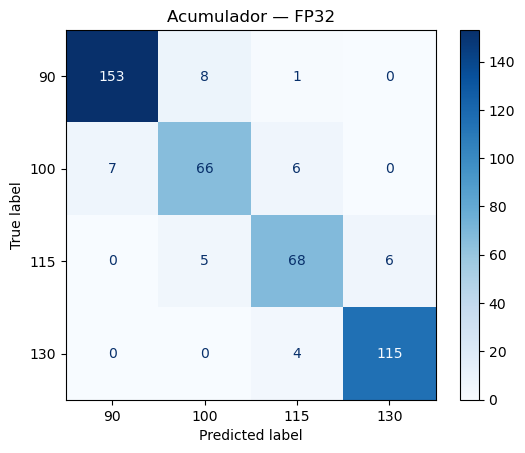


ACUMULADOR — INT8
              precision    recall  f1-score   support

          90     0.9625    0.9506    0.9565       162
         100     0.8519    0.8734    0.8625        79
         115     0.8718    0.8608    0.8662        79
         130     0.9500    0.9580    0.9540       119

    accuracy                         0.9226       439
   macro avg     0.9090    0.9107    0.9098       439
weighted avg     0.9229    0.9226    0.9227       439



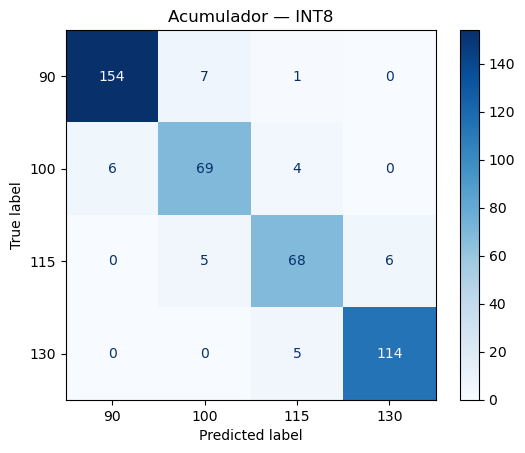

In [81]:
# Análise dos erros de classificação do acumulador

X = X_teste_acumulador
y = y_teste_acumulador

# Previsões FP32
pred_fp32 = modelos_finais["Acumulador"].predict(X)

# Previsões INT8
with np.load(
    pasta / "acumulador_int8_calibrado.npz"
) as dados:

    parametros = {
        chave: dados[chave].copy()
        for chave in dados.files
    }

pred_int8 = prever_int8_numpy(X, parametros)

classes = [90, 100, 115, 130]

# Métricas por classe
for nome, previsoes in [
    ("FP32", pred_fp32),
    ("INT8", pred_int8)
]:

    print(f"\nACUMULADOR — {nome}")

    print(
        classification_report(
            y,
            previsoes,
            labels=classes,
            zero_division=0,
            digits=4
        )
    )

    matriz = confusion_matrix(
        y,
        previsoes,
        labels=classes
    )

    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=classes
    ).plot(cmap="Blues")

    plt.title(f"Acumulador — {nome}")
    plt.show()

In [82]:
# Verificar equivalência do FP32 exportado no conjunto de teste

for componente, X in [
    ("Bomba", X_teste_bomba),
    ("Acumulador", X_teste_acumulador)
]:

    with np.load(
        pasta / f"{componente.lower()}_fp32.npz"
    ) as dados:

        entrada = X.to_numpy(dtype=np.float32)[
            :, dados["indices"]
        ]

        entrada = (
            entrada - dados["media"]
        ) / dados["escala"]

        oculta = np.maximum(
            entrada @ dados["W1"] + dados["b1"],
            np.float32(0)
        )

        saida = oculta @ dados["W2"] + dados["b2"]

        pred_fp32_exportado = dados["classes"][
            np.argmax(saida, axis=1)
        ]

    pred_sklearn = modelos_finais[componente].predict(X)

    divergencias = np.sum(
        pred_fp32_exportado != pred_sklearn
    )

    print(f"{componente}: {divergencias} divergências")

Bomba: 0 divergências
Acumulador: 0 divergências


# Extra: Auditorias

In [83]:
# Auditoria metodológica das divisões de dados
# Não modifica os modelos nem as partições existentes.

componentes = [
    "resfriador", "valvula", "bomba", "acumulador"
]

# Identificar combinações de condições experimentais
condicoes = (
    df_rotulos[componentes]
    .astype(str)
    .agg("|".join, axis=1)
)

auditoria = []

tarefas = [
    (
        "Bomba",
        X_treino_bomba,
        X_teste_bomba,
        divisoes_robustez_bomba
    ),
    (
        "Acumulador",
        X_treino_acumulador,
        X_teste_acumulador,
        divisoes_robustez_acumulador
    )
]

for nome, X_dev, X_teste, divisoes in tarefas:

    indices_dev = set(X_dev.index)
    indices_teste = set(X_teste.index)

    # 1. Verificar compartilhamento de registros
    registros_compartilhados = len(
        indices_dev.intersection(indices_teste)
    )

    # 2. Verificar compartilhamento dos blocos consecutivos
    blocos_dev = set(grupos.loc[X_dev.index])
    blocos_teste = set(grupos.loc[X_teste.index])

    blocos_compartilhados = len(
        blocos_dev.intersection(blocos_teste)
    )

    # 3. Verificar repetição de condições experimentais
    condicoes_dev = set(condicoes.loc[X_dev.index])
    condicoes_teste = set(condicoes.loc[X_teste.index])

    condicoes_compartilhadas = (
        condicoes_dev.intersection(condicoes_teste)
    )

    proporcao_condicoes_repetidas = (
        condicoes.loc[X_teste.index]
        .isin(condicoes_compartilhadas)
        .mean() * 100
    )

    # 4. Verificar registros temporalmente adjacentes
    vizinhos = sum(
        (i - 1 in indices_dev) or (i + 1 in indices_dev)
        for i in indices_teste
    )

    # 5. Verificar linhas de features exatamente repetidas
    duplicatas = X_teste.merge(
        X_dev.drop_duplicates(),
        how="inner",
        on=X_dev.columns.tolist()
    ).shape[0]

    # 6. Verificar cobertura das 20 divisões
    avaliados = set()

    for treino, validacao in divisoes:
        avaliados.update(validacao.tolist())

    cobertura = 100 * len(avaliados) / len(X_dev)

    auditoria.append({
        "Componente": nome,
        "Registros compartilhados": registros_compartilhados,
        "Blocos compartilhados": blocos_compartilhados,
        "Combinações compartilhadas": len(
            condicoes_compartilhadas
        ),
        "Teste em condições vistas (%)":
            proporcao_condicoes_repetidas,
        "Ciclos adjacentes": vizinhos,
        "Features duplicadas": duplicatas,
        "Cobertura validação (%)": cobertura
    })

df_auditoria = pd.DataFrame(auditoria)

display(df_auditoria.round(2))

,Componente,Registros compartilhados,Blocos compartilhados,Combinações compartilhadas,Teste em condições vistas (%),Ciclos adjacentes,Features duplicadas,Cobertura validação (%)
0,Bomba,0,0,13,54.13,54,0,73.48
1,Acumulador,0,0,26,19.13,91,0,62.06


In [84]:
# Desempenho do acumulador em condições vistas e inéditas

componentes = [
    "resfriador", "valvula", "bomba", "acumulador"
]

# Identificar combinações de condições
condicoes = (
    df_rotulos[componentes]
    .astype(str)
    .agg("|".join, axis=1)
)

# Combinações presentes no desenvolvimento
condicoes_dev = set(
    condicoes.loc[X_treino_acumulador.index]
)

# Identificar condições vistas e inéditas no teste
condicoes_teste = condicoes.loc[X_teste_acumulador.index]

tipos = np.where(
    condicoes_teste.isin(condicoes_dev),
    "Vista",
    "Inédita"
)

# Previsões do modelo final FP32
pred = modelos_finais["Acumulador"].predict(
    X_teste_acumulador
)

y = y_teste_acumulador.to_numpy()

# Distribuição das classes
print("Distribuição das classes:")

display(
    pd.crosstab(
        pd.Series(y, name="Classe real"),
        pd.Series(tipos, name="Condição")
    )
)

# Avaliar desempenho dos dois grupos
resultados = []

classes = [90, 100, 115, 130]

for tipo in ["Vista", "Inédita"]:

    mascara = tipos == tipo

    y_real = y[mascara]
    y_pred = pred[mascara]

    # F1 macro somente quando todas as classes estiverem presentes
    todas_classes = set(classes).issubset(set(y_real))

    resultados.append({
        "Condição": tipo,
        "Amostras": len(y_real),
        "Acurácia (%)": 100 * accuracy_score(
            y_real, y_pred
        ),
        "F1 macro (%)": (
            100 * f1_score(
                y_real,
                y_pred,
                labels=classes,
                average="macro",
                zero_division=0
            )
            if todas_classes else np.nan
        )
    })

df_condicoes = pd.DataFrame(resultados)

print("\nDesempenho por condição:")
display(df_condicoes.round(2))

Distribuição das classes:


Condição,Inédita,Vista
Classe real,,
90,130,32
100,72,7
115,62,17
130,91,28



Desempenho por condição:


,Condição,Amostras,Acurácia (%),F1 macro (%)
0,Vista,84,86.90,81.37
1,Inédita,355,92.68,91.88


In [85]:
# Auditoria das cinco divisões do GroupKFold — Acumulador

from sklearn.model_selection import GroupKFold

componentes = [
    "resfriador", "valvula", "bomba", "acumulador"
]

# Grupos utilizados originalmente no GroupKFold
grupos_cv = (
    df_rotulos.loc[X_treino_acumulador.index, componentes]
    .astype(str)
    .agg("|".join, axis=1)
)

# Recuperar os resultados já calculados
f1_por_divisao = df_groupkfold[
    (df_groupkfold["Componente"] == "Acumulador") &
    (df_groupkfold["Modelo"] == "MLP")
].set_index("Divisão")["F1 macro"]

resultados_auditoria_cv = []

divisor = GroupKFold(n_splits=5)

for numero, (treino, validacao) in enumerate(
    divisor.split(
        X_treino_acumulador,
        y_treino_acumulador,
        groups=grupos_cv
    ),
    start=1
):

    y_val = y_treino_acumulador.iloc[validacao]

    distribuicao = (
        y_val.value_counts(normalize=True)
        .reindex([90, 100, 115, 130], fill_value=0)
        * 100
    )

    resultados_auditoria_cv.append({
        "Divisão": numero,
        "Treinamento": len(treino),
        "Validação": len(validacao),
        "Combinações": grupos_cv.iloc[validacao].nunique(),
        "Classe 90 (%)": distribuicao.loc[90],
        "Classe 100 (%)": distribuicao.loc[100],
        "Classe 115 (%)": distribuicao.loc[115],
        "Classe 130 (%)": distribuicao.loc[130],
        "F1 macro (%)": f1_por_divisao.loc[numero] * 100
    })

df_auditoria_cv = pd.DataFrame(resultados_auditoria_cv)

display(df_auditoria_cv.round(2))

print(
    "\nF1 macro médio:",
    round(df_auditoria_cv["F1 macro (%)"].mean(), 2),
    "%"
)

,Divisão,Treinamento,Validação,Combinações,Classe 90 (%),Classe 100 (%),Classe 115 (%),Classe 130 (%),F1 macro (%)
0,1,1407,359,14,72.14,11.14,2.79,13.93,53.95
1,2,1415,351,16,5.98,19.94,14.25,59.83,80.53
2,3,1415,351,16,68.66,5.70,17.09,8.55,61.66
3,4,1412,354,32,23.73,22.60,22.60,31.07,70.46
4,5,1415,351,31,11.68,31.34,34.19,22.79,77.50



F1 macro médio: 68.82 %
